**LUMS · School of Science & Engineering**

# AI 500 — Foundations of AI

## Programming Assignment 3 — Regression & Generalization

*Tasks 3 and 4 · 100 points · UCI Concrete Compressive Strength*

---

**Name:** ____________________ &emsp; **Roll number:** ____________________ &emsp; **Section:** ____________

### Before you start — two separate deliverables in your workflow

**PURPLE TASKS = CODING.** **You write the models, analysis loops, metrics, tables and plots yourself** in the cells marked `TODO`. The notebook provides imports, the dataset download, fixed data splits, shared plotting utilities, and short boilerplate for a technically involved early-stopping setup. **It does not provide the experiment implementations.** The supplied instructor notebook is not distributed.

**GREEN QUESTIONS = REPORT.** You answer **Q1–Q8** in a single PDF using results from your **own code**. **Only that PDF is submitted and graded**; the notebook is working space and is not marked. The fact that code is not collected does not mean coding is optional.

**Working rule:** work from top to bottom; replace every `TODO` and `NotImplementedError`, run a clean kernel restart, and verify that your program creates the requested figures and tables. Use the same seeds, sample splits and hyperparameter search spaces so that the scientific comparisons are reproducible.


### <span style="color:#C03743">Deliverables · read carefully</span>

Submit the **completed regression notebook**, the **completed classification notebook**, and **one combined PDF report** `RollNumber_PA3_Report.pdf` (maximum **18 pages** total, including figures and both model cards). The **report alone is graded**; the code must be written and run by you and may be inspected for academic-integrity checks. Include answers **Q1–Q8** and evidence from **F1–F8b** and **T1–T4** as specifically requested; captions should not be substituted for analysis. The `.ipynb` files must be submitted but are **not independently graded**. All screenshots, metrics and plots must be generated by your own implementation on the official UCI dataset (except the explicitly labeled artificial training-label corruption).

**Scientific integrity:** Keep the final test set sealed until the last cell; preprocessing happens inside a pipeline; controlled corruptions affect training labels only; do not tune on test results; explain limitations of random splits when mixes repeat.

**Suggested software:** Python 3.9+ with `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `scipy`, `ucimlrepo` (see `requirements.txt`). Internet is needed for UCI retrieval unless you have obtained the same dataset locally.

### Report map

| Task | Question | Main scientific judgment | Points | Required evidence |
|:--|:--|:--|--:|:--|
| 3 | **Q1** | Formulate supervised learning and deployment | **12** | Dataset audit |
| 3 | **Q2** | Baseline, linear/polynomial capacity | **14** | **F1, T1** |
| 3 | **Q3** | MSE / MAE / Huber under contamination | **14** | **F2, T2** |
| 3 | **Q4** | Regression metrics, residuals and error slices | **10** | **F3, T3** |
| 4 | **Q5** | Empirical/population risk and bias–variance | **13** | **F4** |
| 4 | **Q6** | L1 vs L2, shrinkage and sparsity | **12** | **F5, T4** |
| 4 | **Q7** | Early stopping as implicit regularization | **10** | **F6** |
| 4 | **Q8** | Five-fold CV, recipe shift and model card | **15** | **F7, F8, F8b** |
| | | **Total** | **100** | |

---

## TASK 3 — The concrete laboratory: set up the prediction problem (50 points)

<span style="color:#C03743; font-size:21px; font-weight:700;">The problem at hand</span>

A materials laboratory supplies concrete to construction firms. Measuring compressive strength means mixing a recipe, curing specimens for a specified **age**, and crushing a sample. The laboratory wants to forecast the strength (MPa) of a specimen from the mixture ingredients and curing age. It may use the forecast to prioritize laboratory tests, **not** to replace mandatory safety tests.

Each row of the official **UCI Concrete Compressive Strength** dataset is a **mix-at-age** observation, with seven ingredient quantities and curing age as predictors. Be aware that the *same recipe can appear at different ages*: random row-wise splitting and generalization to **new recipes** are different questions.

**Dataset:** Yeh (1998), [UCI dataset 165](https://archive.ics.uci.edu/dataset/165/concrete%2Bcompressive%2Bstrength), DOI `10.24432/C5PK67`, CC BY 4.0. No missing values; 1,030 rows and 8 predictors.

**Supplied setup (not graded as coding):** import libraries and provide common plotting/export helpers. Starting from Task 3.2, **you must implement every experiment**. The initial 80/20 sealed-test split is supplied to keep everyone on the same protocol.

In [1]:
# Install once if necessary, then restart and run all:
# %pip install -r requirements.txt
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, HuberRegressor, QuantileRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
np.set_printoptions(precision=4, suppress=True)
print('Python:', sys.version.split()[0])
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import r2_score

# Figure system: consistent type, color-blind-friendly colors, and vector exports.
from matplotlib import ticker, patheffects
from matplotlib.patches import Rectangle
from scipy.stats import norm
from matplotlib.colors import Normalize

INK = '#172B49'
MUTED = '#51647A'
BLUE = '#2764A5'     # training / baseline
TEAL = '#087D75'     # clean validation / Ridge
ORANGE = '#D17C29'   # higher error / Lasso
VIOLET = '#7652A6'   # alternative method
GRID = '#DFE6EE'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.labelsize': 9.5, 'axes.labelcolor': INK,
    'xtick.labelsize': 8.7, 'ytick.labelsize': 8.7,
    'text.color': INK, 'axes.edgecolor': '#AEBCCD',
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID,
    'legend.frameon': False, 'legend.fontsize': 8.3,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'figure.dpi': 120, 'savefig.dpi': 300,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

def panel(ax, letter, title, grid_axis='y'):
    ax.text(-0.09, 1.075, letter, transform=ax.transAxes,
            fontsize=12, fontweight='bold', color=INK, va='bottom')
    ax.set_title(title, loc='left', pad=14)
    ax.grid(True, axis=grid_axis, linewidth=.65, alpha=.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', length=0, pad=5)

def save_figure(fig, name):
    # PNG previews plus scalable, editable vector PDFs/SVGs for reports.
    fig.savefig(OUT / f'{name}.png', dpi=300, facecolor='white', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', facecolor='white', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.svg', facecolor='white', bbox_inches='tight')
    plt.show()

def mean_ci(samples, confidence=.95):
    """Nonparametric percentile bootstrap CI for a sample's mean."""
    a = np.asarray(samples, dtype=float)
    if a.size == 0: return (np.nan, np.nan)
    rng = np.random.default_rng(2026 + a.size)
    draws = rng.choice(a, size=(1500, len(a)), replace=True).mean(axis=1)
    lo, hi = np.quantile(draws, [(1-confidence)/2, (1+confidence)/2])
    return float(lo), float(hi)

print('Figure exports: 300-dpi PNG, editable PDF, and SVG in', OUT.resolve())

Python: 3.12.3
Figure exports: 300-dpi PNG, editable PDF, and SVG in /tmp/claude-1000/-home-abdullah-projects/be93ecb1-2767-461d-9667-55eb3404699d/scratchpad/run/outputs


**Supplied reproducible data setup:** fetch UCI Concrete (ID 165), check its dimensions, and construct the shared development/inner-validation/sealed-test splits. Do not change the random seeds or score `y_test` until the final task. These setup cells are boilerplate; the regression implementations are **your code**.

In [2]:
from ucimlrepo import fetch_ucirepo
concrete = fetch_ucirepo(id=165)
X = concrete.data.features.copy().reset_index(drop=True).apply(pd.to_numeric)
y = concrete.data.targets.iloc[:, 0].astype(float).reset_index(drop=True)
assert X.shape == (1030,8) and y.shape == (1030,)
assert not X.isna().any().any() and not y.isna().any()
feature_names = list(X.columns)
print('Rows, features:', X.shape, 'Target units: MPa')
print('Features:', feature_names)
# Target summary will be printed after the split, not before it.
print('Exactly repeated 8-feature rows:', int(X.duplicated().sum()))
print('Repeated ingredient recipes, ignoring curing age:', int(X.iloc[:,:7].duplicated().sum()))

idx_dev, idx_test = train_test_split(np.arange(len(X)),test_size=.20,random_state=SEED)
X_dev, y_dev = X.iloc[idx_dev], y.iloc[idx_dev]
X_test, y_test = X.iloc[idx_test], y.iloc[idx_test]  # DO NOT inspect until last cell.
idx_in,idx_val = train_test_split(np.arange(len(X_dev)),test_size=.25,random_state=17)
X_in,y_in = X_dev.iloc[idx_in],y_dev.iloc[idx_in]
X_val,y_val = X_dev.iloc[idx_val],y_dev.iloc[idx_val]
print('Development, inner training, inner validation, sealed test sizes:',len(X_dev),len(X_in),len(X_val),len(X_test))
print('Development-only target summary (MPa):')
print(y_dev.describe().round(2).to_string())

Rows, features: (1030, 8) Target units: MPa
Features: ['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age']
Exactly repeated 8-feature rows: 38
Repeated ingredient recipes, ignoring curing age: 603
Development, inner training, inner validation, sealed test sizes: 824 618 206 206
Development-only target summary (MPa):
count    824.00
mean      35.86
std       16.87
min        2.33
25%       23.68
50%       34.08
75%       45.86
max       82.60


<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 3.1 · Define the supervised learning problem [12 points]</span>

**Concept lens · What are we actually learning?** Supervised regression observes labeled examples $(x_i,y_i)$ and learns parameters $\theta$ of a function $f_\theta(x)$. The target $y$ is continuous and is different from both the prediction $\hat y$ and the loss $L(y,\hat y)$. **Hyperparameters** (degree, alpha, loss choice) are selected using validation evidence; they are not the same as learned coefficients.

Use the printed audit to answer **Q1**. Your answer must say what is available **at prediction time**, not merely what appears in a spreadsheet.

<span style="color:#16845B; font-size:19px; font-weight:700;">**Question Q1 · Problem specification (12 points)**</span>

**(a) [5]** State $\mathcal D$, a row's unit, $X\in\mathbb R^{n\times d}$, $y\in\mathbb R^n$, the seven mixture inputs plus age, the output unit, and the decision time. Explain why a curing-age measurement is allowed but *later test strength* is not a usable feature.  
**(b) [4]** Write a linear predictor $\hat y=f_\theta(x)$ and the empirical **MSE training objective**, distinguishing intercept, coefficients, fitted parameters, and hyperparameters.  
**(c) [3]** Your employer wants predictions for *never-before-tested recipes*. Do the repeated recipes in this dataset change what you mean by a representative test split? Suggest a better evaluation design and one residual risk.

**Answer:**

**(a)** $\mathcal D=\{(x_i,y_i)\}_{i=1}^{n}$, with $n=1030$ rows. Each row is a **mix-at-age observation**: one concrete recipe, cured for a given number of days, and then crushed. $X\in\mathbb R^{n\times d}$ with $d=8$. The columns are seven mixture quantities (kg per m³ of mix): Cement, Blast-Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate and Fine Aggregate, plus curing **Age** (days). $y\in\mathbb R^n$ is the measured compressive strength in **MPa**, and the prediction $\hat y$ is also in MPa. The forecast is made at **decision time**: when a recipe and a planned test age are known, *before* the specimen is crushed. All eight inputs are known then — the mix is designed in advance, and the curing age is a planned test condition, not an outcome. A later strength measurement (for example, the 7-day result used to predict 28-day strength, or any test of the same specimen) is not available at prediction time for a new mix. It is also a near-copy of the target, so using it would be **target leakage**. Scores would look excellent but could not be reproduced in deployment. (The development split has 824 rows with mean strength 35.9 MPa, SD 16.9, range 2.3–82.6 MPa. 38 rows repeat all 8 features and 603 rows repeat an ingredient recipe seen at another age.)

**(b)** Linear predictor: $\hat y=f_\theta(x)=b+w^\top x=b+\sum_{j=1}^{8}w_jx_j$, where $\theta=(b,w)$. The intercept $b$ is the baseline prediction at $x=0$ (or at the mean input after standardisation), and the coefficients $w_j$ give the change in predicted MPa per unit of input $j$, holding the others fixed. Both are **fitted parameters**, learned by minimising the empirical MSE:
$$\hat\theta=\arg\min_{b,w}\ \frac1n\sum_{i=1}^{n}\big(y_i-b-w^\top x_i\big)^2 .$$
**Hyperparameters** are set *before* fitting and chosen on validation data, not by this objective: polynomial degree, Ridge/Lasso penalty $\alpha$, choice of loss, Huber $\delta$, GD learning rate and number of epochs. The scaler means and SDs are also fitted quantities (preprocessing parameters), fitted only on training data.

**(c)** Yes. Because the same recipe appears at several ages (373 distinct recipes among 824 development rows), a random row split usually puts the same recipe in both training and test sets, at different ages. The model then only needs to *interpolate along age for a known recipe*, which is easier than predicting a recipe it has never seen. For never-before-tested recipes, a representative evaluation must hold out **whole recipes**: grouped splits / `GroupKFold` with the seven-ingredient vector as the group, ideally followed by a final test on recipes kept out of all development. A residual risk remains even then. New recipes may lie **outside the training ingredient ranges** or use different cement/admixture products, suppliers or curing conditions (a covariate and concept shift that grouping by identical recipe cannot reveal). Near-identical recipes (differing by a few kg) still count as "new" groups, so grouped CV can be mildly optimistic.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 3.2 · A straight line versus a feature explosion [14 points]</span>

**Concept lens · Model capacity.** A **mean baseline** predicts a constant. A **linear model** uses one coefficient per input; **polynomial regression** is still linear in its learned coefficients, but introduces powers and interactions of inputs. Degree $d$ with eight original features creates $\binom{8+d}{d}-1$ non-constant terms. The additional flexibility can lower training error but can also fit noise, especially when the number of terms exceeds the number of fitting records.

**Experiment:** fit a mean baseline and degrees 1–5, holding the small Ridge penalty fixed. **F1** overlays inner-training and inner-validation RMSE and shows the number of features. **T1** reports both MAE and RMSE. The fixed penalty is used for numerical stability, **not** for hyperparameter selection.

**Figure-reading note:** F1 separates (A) training/validation error, (B) their *difference*, and (C) the number of basis terms. Do not call the generalization gap a population-risk estimate.

**Coding deliverable (implement it yourself):** `model_ridge`, `score`, `T1` and the three-panel `F1_capacity` figure. Use `DummyRegressor`, degree 1–5 polynomial features and identical light Ridge penalty. Save `T1_capacity.csv`. The provided cell is only a scaffold.

n_inner = 618, n_val = 206  (errors in MPa; inner-training vs inner-validation)


,model,degree,terms,train_mae,val_mae,train_rmse,val_rmse,gap_rmse
0,Mean baseline,0,0,13.820,12.843,17.236,15.660,-1.576
1,Linear (Ridge 0.01),1,8,8.351,8.185,10.481,10.805,0.325
2,Poly deg 2 (Ridge 0.01),2,44,5.443,6.189,7.088,8.154,1.066
3,Poly deg 3 (Ridge 0.01),3,164,3.315,4.729,4.260,6.575,2.315
4,Poly deg 4 (Ridge 0.01),4,494,1.484,7.847,2.306,16.054,13.747
5,Poly deg 5 (Ridge 0.01),5,1286,0.902,9.186,1.765,23.088,21.323


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


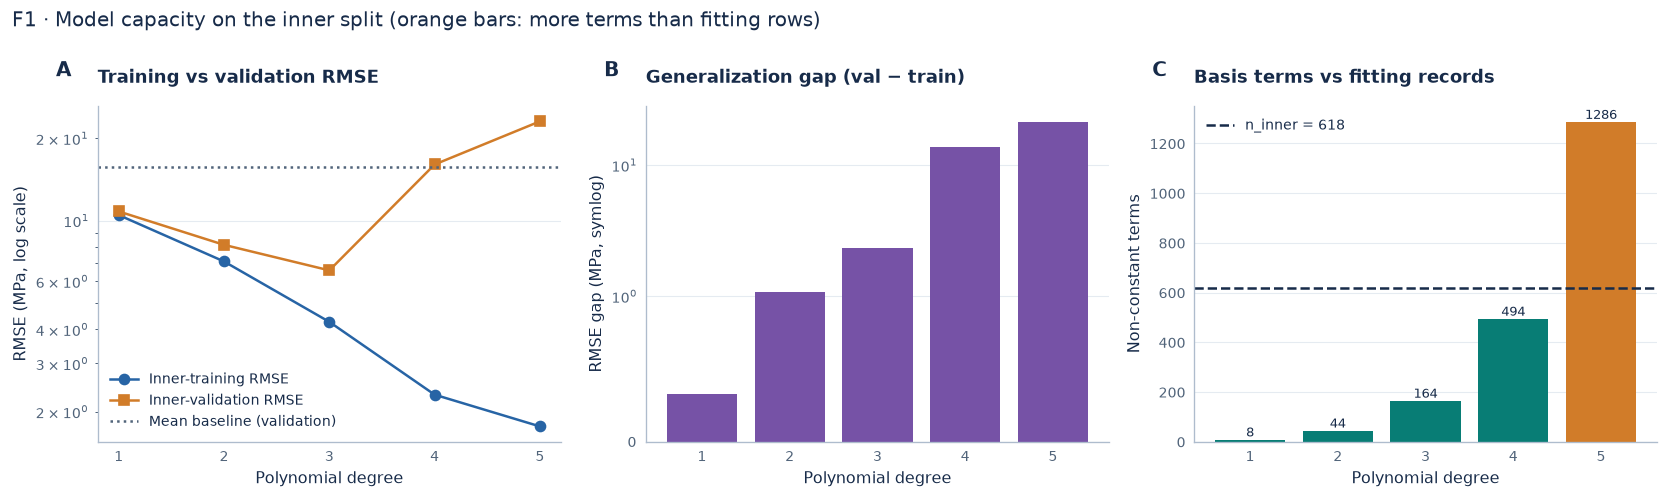

In [3]:
# TASK 3.2 — IMPLEMENT: mean baseline, linear/poly capacity sweep, F1 and T1.
# The input data have already been split. Do NOT read X_test or y_test here.
from math import comb

def model_ridge(degree, alpha=1.0):
    """Return a leakage-safe Pipeline: scale inputs -> polynomial -> scale -> Ridge."""
    return Pipeline([
        ('scale_inputs', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scale_expanded', StandardScaler()),
        ('reg', Ridge(alpha=alpha)),
    ])

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def score(model, xa, ya, xb, yb):
    """Fit ONLY on (xa, ya). Return train/validation MAE and RMSE."""
    model.fit(xa, ya)
    pa, pb = model.predict(xa), model.predict(xb)
    return {'train_mae': float(mean_absolute_error(ya, pa)), 'val_mae': float(mean_absolute_error(yb, pb)),
            'train_rmse': rmse(ya, pa), 'val_rmse': rmse(yb, pb)}

def n_terms(degree, d=8):
    return comb(d + degree, degree) - 1

capacity = []
capacity.append({'model': 'Mean baseline', 'degree': 0, 'terms': 0,
                 **score(DummyRegressor(strategy='mean'), X_in, y_in, X_val, y_val)})
for degree in [1, 2, 3, 4, 5]:
    m = model_ridge(degree, alpha=0.01)
    res = score(m, X_in, y_in, X_val, y_val)
    terms = m.named_steps['poly'].n_output_features_
    assert terms == n_terms(degree)
    capacity.append({'model': 'Linear (Ridge 0.01)' if degree == 1 else f'Poly deg {degree} (Ridge 0.01)',
                     'degree': degree, 'terms': terms, **res})

T1 = pd.DataFrame(capacity)
T1['gap_rmse'] = T1['val_rmse'] - T1['train_rmse']
T1.to_csv(OUT / 'T1_capacity.csv', index=False)
print(f'n_inner = {len(X_in)}, n_val = {len(X_val)}  (errors in MPa; inner-training vs inner-validation)')
display(T1.round(3))

poly = T1[T1.degree > 0]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ax = axes[0]; panel(ax, 'A', 'Training vs validation RMSE')
ax.plot(poly.degree, poly.train_rmse, 'o-', color=BLUE, label='Inner-training RMSE')
ax.plot(poly.degree, poly.val_rmse, 's-', color=ORANGE, label='Inner-validation RMSE')
ax.axhline(T1.loc[0, 'val_rmse'], color=MUTED, ls=':', label='Mean baseline (validation)')
ax.set_yscale('log'); ax.set_xticks([1, 2, 3, 4, 5]); ax.set_xlabel('Polynomial degree'); ax.set_ylabel('RMSE (MPa, log scale)'); ax.legend()
ax = axes[1]; panel(ax, 'B', 'Generalization gap (val − train)')
ax.bar(poly.degree, poly.gap_rmse, color=VIOLET)
ax.set_yscale('symlog', linthresh=1); ax.set_xlabel('Polynomial degree'); ax.set_ylabel('RMSE gap (MPa, symlog)')
ax = axes[2]; panel(ax, 'C', 'Basis terms vs fitting records')
ax.bar(poly.degree, poly.terms, color=[TEAL if t < len(X_in) else ORANGE for t in poly.terms])
ax.axhline(len(X_in), color=INK, ls='--', label=f'n_inner = {len(X_in)}')
for dg, t in zip(poly.degree, poly.terms): ax.text(dg, t, str(t), ha='center', va='bottom', fontsize=8)
ax.set_xlabel('Polynomial degree'); ax.set_ylabel('Non-constant terms'); ax.legend()
fig.suptitle('F1 · Model capacity on the inner split (orange bars: more terms than fitting rows)', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F1_capacity')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q2 · When does flexibility become a liability? [14 points]</span>

**(a) [3]** Compare mean, linear and polynomial models using **T1**. Give one substantive reason a constant baseline is scientifically valuable.  
**(b) [4]** Derive/verify the degree-2, 3, 4 and 5 feature counts. At which degree does the number of coefficients exceed $n_{inner}$? Does this *prove* overfitting?  
**(c) [4]** Identify a regime with falling training RMSE and rising validation RMSE. Why does $d=5$ not automatically win?  
**(d) [3]** A colleague concludes, “The coefficient on cement is negative in the high-degree model, so cement weakens concrete.” Give two reasons that inference is unjustified.

**Answer:**

**T1 · Inner-training (n = 618) vs inner-validation (n = 206) errors, Ridge α = 0.01 (MPa).**

| Model | Terms | Train MAE | Val MAE | Train RMSE | Val RMSE |
|---|---:|---:|---:|---:|---:|
| Mean baseline | 0 | 13.82 | 12.84 | 17.24 | 15.66 |
| Linear (deg 1) | 8 | 8.35 | 8.19 | 10.48 | 10.81 |
| Poly deg 2 | 44 | 5.44 | 6.19 | 7.09 | 8.15 |
| **Poly deg 3** | 164 | 3.32 | **4.73** | 4.26 | **6.58** |
| Poly deg 4 | 494 | 1.48 | 7.85 | 2.31 | 16.05 |
| Poly deg 5 | 1286 | 0.90 | 9.19 | 1.77 | 23.09 |

**(a)** The linear model cuts validation RMSE from 15.66 (mean) to 10.81 MPa. Degree 2 lowers it to 8.15 and degree 3 to 6.58 MPa (MAE 4.73), the best validation result. Strength is non-linear in its inputs (e.g. it rises steeply with age early on and then flattens, and the effect of the water/cement balance is not linear), and low-order interactions capture this. A constant baseline is scientifically valuable because it is the error you get with **no** information from the inputs. It sets a floor that any useful model must beat (R² is defined relative to it), and it exposes broken models: degree 5's validation RMSE of 23.1 MPa is *worse than predicting the mean*. A model that does not clearly beat the baseline has learned nothing transferable.

**(b)** Number of non-constant terms is $\binom{8+d}{d}-1$: $d=2$: $\binom{10}{2}-1=45-1=44$; $d=3$: $\binom{11}{3}-1=165-1=164$; $d=4$: $\binom{12}{4}-1=495-1=494$; $d=5$: $\binom{13}{5}-1=1287-1=1286$ (all confirmed by `n_output_features_`). With $n_{inner}=618$, the coefficient count first exceeds the number of fitting rows at **degree 5** (1286 > 618; degree 4 has 494 < 618, but already less than 1.3 rows per coefficient). This does **not prove** overfitting. $p>n$ means the unpenalised least-squares solution is not unique and can interpolate the training data, but regularisation (here a small Ridge penalty) selects one solution and can still generalise. Overfitting is shown empirically, by the held-out error, not by the parameter count.

**(c)** From degree 3 to 4 to 5, training RMSE keeps falling (4.26 → 2.31 → 1.77 MPa) while validation RMSE rises sharply (6.58 → 16.05 → 23.09 MPa). The gap grows from 2.3 to 13.7 to 21.3 MPa (F1B). This is the over-fitting regime: the extra terms fit noise and quirks of the 618 training rows, and the high-order terms extrapolate wildly on validation points slightly outside the training region. Degree 5 does not win because it was optimised for the **training** objective. Lower training error says nothing about error on new mixes, and model selection must use held-out error, where degree 3 is best.

**(d)** (1) **Collinearity and basis entanglement.** In a degree-5 basis, "cement" appears in hundreds of terms (Cement², Cement·Water, Cement·Age², …). The linear coefficient is only the slope holding every other term fixed — an impossible scenario, since Cement² cannot stay fixed while Cement changes — and with standardised, highly correlated terms the coefficients are unstable and can switch sign. The model's *overall* response to more cement (its partial dependence) can be positive even if one coefficient is negative. (2) **Prediction ≠ causation.** The model is fitted to observational recipe data in which ingredient quantities were chosen together (more cement often comes with less slag or fly ash, or a different water content). Coefficients describe associations in this dataset, not the effect of an intervention. They also come from an over-fitted model whose validation error is worse than the mean baseline, so its coefficients are not even reliable for prediction. Materials science and controlled experiments, not this coefficient, decide whether cement strengthens concrete.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 3.3 · When labels fail: MSE, MAE and Huber [14 points]</span>

**Concept lens · A loss expresses what counts as a costly mistake.** With residual $r=y-\hat y$, squared loss grows as $r^2$, absolute loss as $|r|$, and Huber loss is quadratic near zero and linear for large $|r|$. In this experiment, we deliberately **change selected training targets** (not features or validation targets) to imitate transcription errors. Real extreme strength measurements could be valid, so robustness is **not automatically desirable**.

**F2a** shows penalty geometry. **F2b and T2** compare OLS, robust Huber and median/quantile regression over **0%, 5%, 10%** label contamination. **Important nuance:** `HuberRegressor(epsilon=...)` uses its own internal residual scaling, so its `epsilon` is **not the plotted Huber delta in MPa**. We compare qualitative behavior, not claim that the plotted formula numerically matches the scikit-learn objective.

**Figure-reading note:** In F2A, losses are divided by their value at a 20 MPa residual to compare *shape*, not absolute numerical magnitude. In F2B, faint points are all six corruption replicates; solid lines are their means.

**Coding deliverable:** Implement MSE, MAE, and Huber losses; compare the OLS, Huber and median-regression estimators using six repeated **training-only** corruption draws for each of 0%, 5%, and 10%. Produce `T2` and `F2_losses`. Keep the validation labels unchanged.

T2 · Validation error (clean labels) after SYNTHETIC corruption of inner-training labels; 6 replicates; MAE in MPa, MSE in MPa².


,method,corruption,val_MAE_mean,val_MAE_sd,val_MSE_mean,val_MSE_sd,val_RMSE_mean,MAE_increase_vs_clean
0,Huber,0.00,8.211,0.000,126.567,0.000,11.250,0.000
1,Huber,0.05,8.302,0.082,132.109,4.797,11.492,0.091
2,Huber,0.10,8.377,0.084,139.630,10.034,11.810,0.166
3,Median / quantile (MAE),0.00,8.308,0.000,138.150,0.000,11.754,0.000
4,Median / quantile (MAE),0.05,8.512,0.116,149.216,5.365,12.214,0.204
5,Median / quantile (MAE),0.10,8.556,0.105,153.812,5.949,12.400,0.248
6,OLS (squared loss),0.00,8.185,0.000,116.753,0.000,10.805,0.000
7,OLS (squared loss),0.05,8.619,0.090,131.559,2.552,11.469,0.433
8,OLS (squared loss),0.10,9.491,0.162,156.551,4.482,12.511,1.306


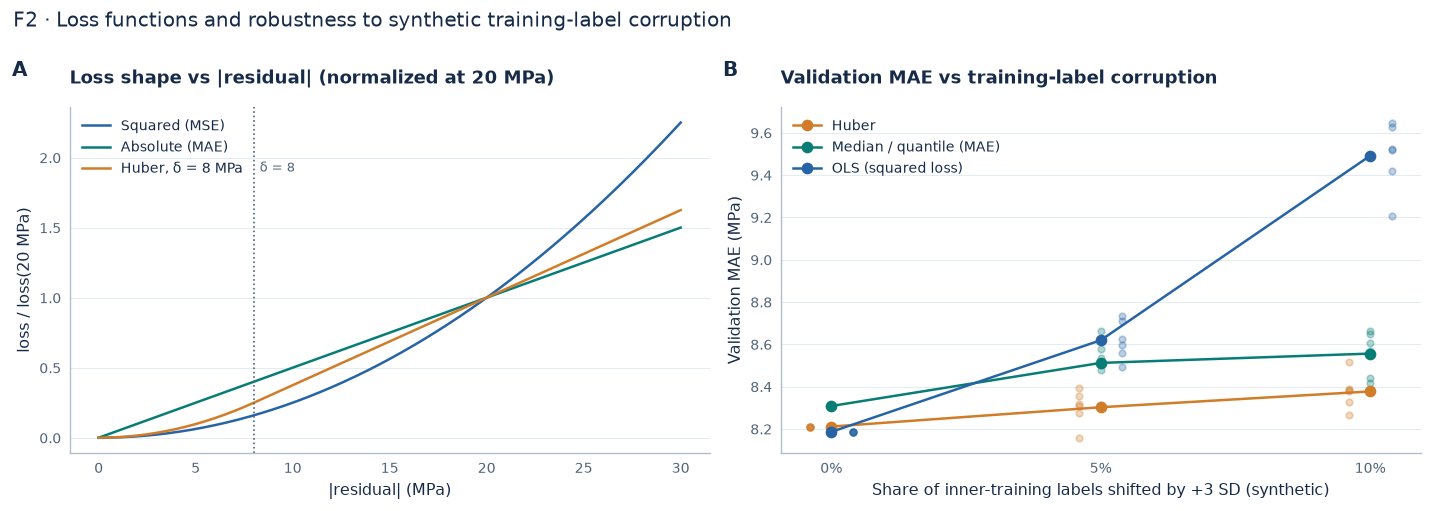

In [4]:
# TASK 3.3 — IMPLEMENT: three losses, repeated label corruption, F2 and T2.
from sklearn.exceptions import ConvergenceWarning

def mse(y_true, y_pred):
    """Mean SQUARED error; units MPa²."""
    r = np.asarray(y_true, float) - np.asarray(y_pred, float)
    return float(np.mean(r ** 2))

def mae(y_true, y_pred):
    """Mean absolute error; units MPa."""
    r = np.asarray(y_true, float) - np.asarray(y_pred, float)
    return float(np.mean(np.abs(r)))

def huber(y_true, y_pred, delta=8.0):
    """Piecewise quadratic/linear loss with residual threshold in MPa."""
    a = np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))
    return float(np.mean(np.where(a <= delta, 0.5 * a ** 2, delta * (a - 0.5 * delta))))

# Self-checks; these MUST pass before attempting the experiment.
assert np.isclose(mse([0, 0], [2, 20]), 202)
assert np.isclose(mae([0, 0], [2, 20]), 11)
assert np.isclose(huber([0, 0], [2, 20], 8), 65)

methods = {
    'OLS (squared loss)': lambda: Pipeline([('scale', StandardScaler()), ('reg', LinearRegression())]),
    'Huber': lambda: Pipeline([('scale', StandardScaler()), ('reg', HuberRegressor(epsilon=1.35, alpha=0.0, max_iter=2000))]),
    'Median / quantile (MAE)': lambda: Pipeline([('scale', StandardScaler()),
                                                 ('reg', QuantileRegressor(quantile=0.5, alpha=0, solver='highs'))]),
}

records = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for fraction in [0.0, 0.05, 0.10]:
        for rep in range(6):
            rng = np.random.default_rng(7000 + rep)
            y_corrupt = y_in.to_numpy(copy=True)
            k = int(round(fraction * len(y_corrupt)))
            bad = rng.choice(len(y_corrupt), size=k, replace=False)
            y_corrupt[bad] += 3 * y_in.std()          # SYNTHETIC corruption of TRAINING labels only
            for name, factory in methods.items():
                model = factory().fit(X_in, y_corrupt)
                pred = model.predict(X_val)           # validation labels unchanged
                records.append({'method': name, 'corruption': fraction, 'rep': rep, 'n_corrupted': k,
                                'val_MAE': mae(y_val, pred), 'val_MSE': mse(y_val, pred),
                                'val_RMSE': np.sqrt(mse(y_val, pred))})

loss_runs = pd.DataFrame(records)
T2 = (loss_runs.groupby(['method', 'corruption'])
      .agg(val_MAE_mean=('val_MAE', 'mean'), val_MAE_sd=('val_MAE', 'std'),
           val_MSE_mean=('val_MSE', 'mean'), val_MSE_sd=('val_MSE', 'std'),
           val_RMSE_mean=('val_RMSE', 'mean'))
      .reset_index())
clean = T2[T2.corruption == 0].set_index('method')['val_MAE_mean']
T2['MAE_increase_vs_clean'] = T2.apply(lambda r: r.val_MAE_mean - clean[r.method], axis=1)
T2.to_csv(OUT / 'T2_loss_robustness.csv', index=False)
print('T2 · Validation error (clean labels) after SYNTHETIC corruption of inner-training labels; 6 replicates; MAE in MPa, MSE in MPa².')
display(T2.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]; panel(ax, 'A', 'Loss shape vs |residual| (normalized at 20 MPa)')
r = np.linspace(0, 30, 301)
sq, ab = r ** 2, r
hb = np.where(r <= 8, 0.5 * r ** 2, 8 * (r - 4))
for vals, lab, col in [(sq, 'Squared (MSE)', BLUE), (ab, 'Absolute (MAE)', TEAL), (hb, 'Huber, δ = 8 MPa', ORANGE)]:
    ax.plot(r, vals / np.interp(20, r, vals), color=col, label=lab)
ax.axvline(8, color=MUTED, ls=':', lw=1); ax.text(8.3, 1.9, 'δ = 8', color=MUTED, fontsize=8)
ax.set_xlabel('|residual| (MPa)'); ax.set_ylabel('loss / loss(20 MPa)'); ax.legend()
ax = axes[1]; panel(ax, 'B', 'Validation MAE vs training-label corruption')
cols = {'OLS (squared loss)': BLUE, 'Huber': ORANGE, 'Median / quantile (MAE)': TEAL}
for i, (name, g) in enumerate(loss_runs.groupby('method')):
    jitter = (i - 1) * 0.004
    ax.scatter(g.corruption * 1 + jitter, g.val_MAE, color=cols[name], alpha=.3, s=16)
    m = T2[T2.method == name]
    ax.plot(m.corruption, m.val_MAE_mean, 'o-', color=cols[name], label=name)
ax.set_xticks([0, .05, .10]); ax.set_xticklabels(['0%', '5%', '10%'])
ax.set_xlabel('Share of inner-training labels shifted by +3 SD (synthetic)'); ax.set_ylabel('Validation MAE (MPa)')
ax.legend()
fig.suptitle('F2 · Loss functions and robustness to synthetic training-label corruption', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F2_losses')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q3 · Robust losses without slogans [14 points]</span>

**(a) [4]** Write the MSE, MAE and Huber objectives with the Huber transition $\delta$ and evaluate **one residual** $r=20$ MPa under all three when $\delta=8$ MPa. Keep the different loss units/conventions visible.  
**(b) [4]** Use **T2** to compare deterioration at 10% corruption. Why might the ranking change if you evaluated by MSE instead of MAE?  
**(c) [3]** Explain why a 60-MPa measurement could be either a mistake or a legitimate high-strength concrete batch, and how that changes the “best” loss.  
**(d) [3]** Choose a loss/metric for typical strength planning and one for **underprediction-sensitive structural review**. Can a symmetric loss directly encode a larger penalty for underprediction? Defend your answer.

**Answer:**

**(a)** With residual $r_i=y_i-\hat y_i$:
$$\text{MSE}=\frac1n\sum_i r_i^2\ \ [\text{MPa}^2],\qquad \text{MAE}=\frac1n\sum_i |r_i|\ \ [\text{MPa}],$$
$$\text{Huber}_\delta=\frac1n\sum_i \ell_\delta(r_i),\quad \ell_\delta(r)=\begin{cases}\tfrac12 r^2 & |r|\le\delta\\ \delta\,(|r|-\tfrac12\delta) & |r|>\delta\end{cases}\ \ [\text{MPa}^2].$$
For one residual $r=20$ MPa and $\delta=8$ MPa: squared loss $=20^2=$ **400 MPa²** (or 200 MPa² under the $\tfrac12 r^2$ convention), absolute loss $=$ **20 MPa**, Huber $=8\,(20-4)=$ **128 MPa²**. Huber is quadratic, and matches $\tfrac12 r^2$, for $|r|\le 8$. Beyond that it grows only linearly, with slope $\delta$, so a 20 MPa residual costs 128 rather than 200. MAE's gradient is bounded ($\pm1$); MSE's gradient grows like $2r$, so one large residual pulls the fit strongly.

**(b)** **T2 · Clean inner-validation error after SYNTHETIC +3 SD (+51.7 MPa) shifts of inner-training labels; mean (SD) of 6 replicates.**

| Method | MAE 0% | MAE 5% | MAE 10% | Δ MAE at 10% | MSE 0% | MSE 10% |
|---|---:|---:|---:|---:|---:|---:|
| OLS (squared) | 8.19 | 8.62 (0.09) | 9.49 (0.16) | **+1.31** | 116.8 | 156.6 (4.5) |
| Huber | 8.21 | 8.30 (0.08) | 8.38 (0.08) | +0.17 | 126.6 | 139.6 (10.0) |
| Median (MAE) | 8.31 | 8.51 (0.12) | 8.56 (0.11) | +0.25 | 138.2 | 153.8 (5.9) |

With clean labels OLS is (slightly) best on both metrics. At 10% corruption OLS deteriorates by +1.31 MPa MAE (+16%) because every shifted label contributes a squared residual that drags the fitted plane upward. Huber (+0.17) and median regression (+0.25) barely move because their influence per point is bounded. If we evaluated by **MSE** the ranking would change. Median regression, which looked clearly better than OLS by MAE (8.56 vs 9.49), is almost as bad as OLS by MSE (153.8 vs 156.6 MPa²). With clean labels it is the *worst* by MSE (138.2 vs 116.8). The median fit ignores the size of large residuals, so it leaves more large errors on validation, and MSE punishes exactly those. A metric is itself a loss: each metric favours the estimator that optimises it.

**(c)** A 60 MPa label can be a **transcription error** (for example 16 typed as 60, or a wrong age recorded). It can also be a **legitimate high-performance concrete** — low water/cement ratio, superplasticizer, long curing (the data reach 82.6 MPa). The statistics alone cannot tell them apart; that needs domain checks (consistency with the recipe and age, the lab log, re-tests). If it is an error, robust losses (Huber/MAE) protect the model. If it is real, down-weighting it biases the model against exactly the high-strength mixes where large values matter, and squared loss, which tries to fit it, is more appropriate. The "best" loss therefore depends on the data-generating process, not on a slogan that robustness is always good.

**(d)** For **typical strength planning** (scheduling and prioritising tests), I would use MAE as the metric. It is in MPa, easy to explain, and not dominated by a few outliers. Huber is a good training loss for this: efficient like MSE for normal errors but robust to transcription errors. For **underprediction-sensitive structural review**, I read "underprediction-sensitive" as concern about *over*-estimating strength. Predicting more strength than the concrete really has ($\hat y>y$) is the unsafe error, so the costly error must be penalised more. I would use an **asymmetric pinball (quantile) loss**, $\rho_\tau(r)=\max(\tau r,(\tau-1)r)$ with a low quantile (e.g. $\tau=0.05$–0.10), which gives a conservative lower-bound prediction, and evaluate one-sided coverage (the share of specimens with $y<\hat y$). A **symmetric** loss cannot encode this. MSE, MAE and Huber depend only on $|r|$, so over- and under-prediction of the same size cost the same and the fitted model targets the conditional mean or median. Asymmetry has to come from an asymmetric loss, a quantile model or a shifted decision threshold (e.g. prediction minus a safety margin). Even then, this is decision support, not a replacement for the mandatory crushing test.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 3.4 · Error is not one number [10 points]</span>

**Concept lens · Regression evaluation.** MAE is an average absolute error in **MPa**. RMSE penalizes large residuals more heavily and is also in **MPa**. $R^2=1-\text{SSE}/\text{SST}$ evaluates the fit relative to a mean-baseline, but it can be negative on held-out data. Signed mean error $\frac1n\sum(\hat y-y)$ reveals net over- or underprediction; opposite errors can cancel.

**F3** examines error versus *measured strength* and by curing-age slice (≤28, 29–90, >90 days). This is an **error-slice audit**, not probability calibration and not a causal fairness study.

**Figure-reading note:** F3B plots percentile-bootstrap 95% intervals for the *subgroup mean absolute error*, conditional on the fitted model and this particular validation set. These intervals are not uncertainty bounds for an individual future prediction and are not evidence of causality.

**Coding deliverable:** Build a degree-3 Ridge error audit on the inner validation data. Calculate MAE, RMSE, $R^2$, signed error and tolerance coverage; tabulate three curing-age slices with sample sizes and bootstrap intervals, then create `T3` and `F3_error_audit`.

Inner-validation audit (degree-3 Ridge, alpha=1; n = 206 )


,value
MAE_MPa,4.765
RMSE_MPa,6.195
R2,0.843
signed_error_MPa (ŷ−y),0.630
pct_within_5MPa,60.680
max_abs_error_MPa,21.764


T3 · Curing-age error slices on the inner-validation split (MPa).


,age_slice,n,MAE_MPa,CI95_low_MPa,CI95_high_MPa,RMSE_MPa,signed_error_MPa,pct_within_5MPa
0,≤28 days,146,4.80,4.19,5.44,6.18,0.05,58.90
1,29–90 days,29,4.20,2.93,5.59,5.54,1.26,68.97
2,>90 days,31,5.12,3.60,6.78,6.83,2.77,61.29


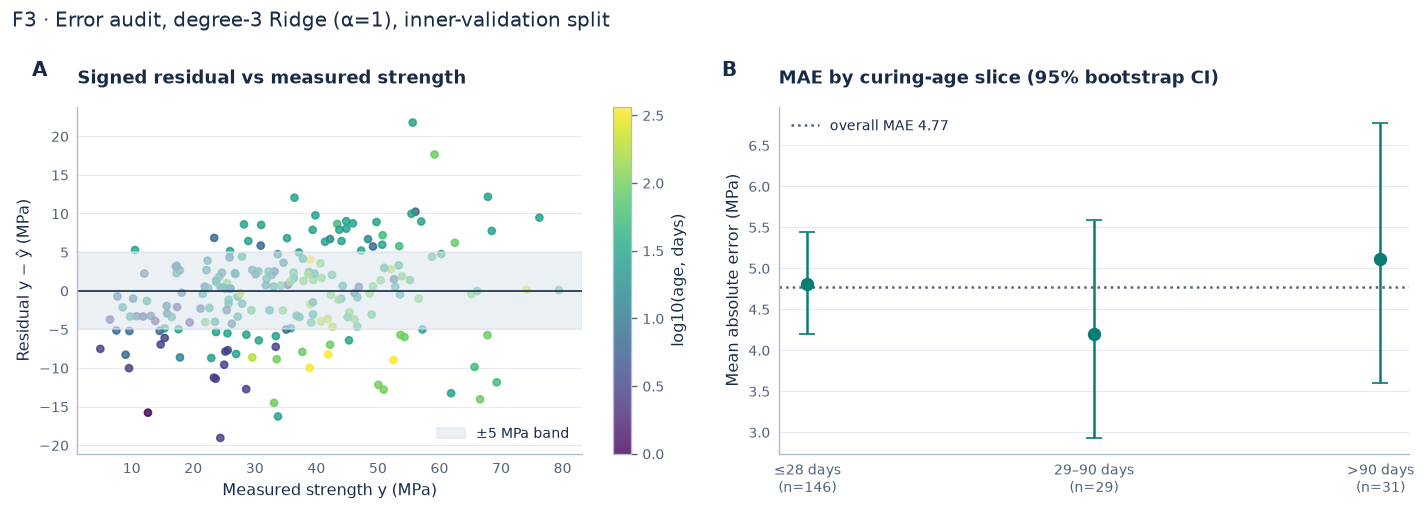

In [5]:
# TASK 3.4 — IMPLEMENT: metric audit, age slices and bootstrap 95% intervals.
# Use fixed audit model: degree=3, Ridge alpha=1, and INNER split only.
audit = model_ridge(degree=3, alpha=1.0)
audit.fit(X_in, y_in)
pred_val = audit.predict(X_val)
resid = y_val.to_numpy() - pred_val            # signed residual r = y - y_hat
pred_err = pred_val - y_val.to_numpy()         # signed prediction error y_hat - y
abs_err = np.abs(resid)

overall = {
    'MAE_MPa': mae(y_val, pred_val), 'RMSE_MPa': rmse(y_val, pred_val),
    'R2': float(r2_score(y_val, pred_val)), 'signed_error_MPa (ŷ−y)': float(pred_err.mean()),
    'pct_within_5MPa': float(100 * np.mean(abs_err <= 5)),
    'max_abs_error_MPa': float(abs_err.max()),
}
print('Inner-validation audit (degree-3 Ridge, alpha=1; n =', len(y_val), ')')
display(pd.Series(overall).round(3).to_frame('value'))

age = X_val['Age'].to_numpy()
windows = [
    ('≤28 days', age <= 28),
    ('29–90 days', (age > 28) & (age <= 90)),
    ('>90 days', age > 90),
]
rows = []
for name, mask in windows:
    if mask.sum() == 0:
        continue
    lo, hi = mean_ci(abs_err[mask])
    rows.append({'age_slice': name, 'n': int(mask.sum()), 'MAE_MPa': abs_err[mask].mean(),
                 'CI95_low_MPa': lo, 'CI95_high_MPa': hi,
                 'RMSE_MPa': float(np.sqrt(np.mean(resid[mask] ** 2))),
                 'signed_error_MPa': float(pred_err[mask].mean()),
                 'pct_within_5MPa': float(100 * np.mean(abs_err[mask] <= 5))})
T3 = pd.DataFrame(rows)
T3.to_csv(OUT / 'T3_error_slices.csv', index=False)
print('T3 · Curing-age error slices on the inner-validation split (MPa).')
display(T3.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]; panel(ax, 'A', 'Signed residual vs measured strength')
sc = ax.scatter(y_val, resid, c=np.log10(age), cmap='viridis', s=18, alpha=.8)
ax.axhline(0, color=INK, lw=1); ax.axhspan(-5, 5, color=GRID, alpha=.6, label='±5 MPa band')
cb = fig.colorbar(sc, ax=ax); cb.set_label('log10(age, days)')
ax.set_xlabel('Measured strength y (MPa)'); ax.set_ylabel('Residual y − ŷ (MPa)'); ax.legend(loc='lower right')
ax = axes[1]; panel(ax, 'B', 'MAE by curing-age slice (95% bootstrap CI)')
xs = np.arange(len(T3))
ax.errorbar(xs, T3.MAE_MPa, yerr=[T3.MAE_MPa - T3.CI95_low_MPa, T3.CI95_high_MPa - T3.MAE_MPa],
            fmt='o', color=TEAL, capsize=5, ms=7)
ax.axhline(overall['MAE_MPa'], color=MUTED, ls=':', label=f"overall MAE {overall['MAE_MPa']:.2f}")
ax.set_xticks(xs); ax.set_xticklabels([f'{a}\n(n={n})' for a, n in zip(T3.age_slice, T3.n)])
ax.set_ylabel('Mean absolute error (MPa)'); ax.legend()
fig.suptitle('F3 · Error audit, degree-3 Ridge (α=1), inner-validation split', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F3_error_audit')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q4 · The failure mode behind the average [10 points]</span>

**(a) [4]** Report inner-validation MAE, RMSE, $R^2$ and signed bias. Explain why a near-zero signed bias cannot certify accurate predictions.  
**(b) [3]** Identify the most challenging **F3/T3** age slice, compare its sample count, and offer two plausible explanations **without making an unsupported causal claim**.  
**(c) [3]** A procurement officer demands predictions within ±5 MPa for **every** mix. Can the displayed overall MAE guarantee that? Which further diagnostic would you request?

**Answer:**

**T3 · Degree-3 Ridge (α = 1), fit on inner-training, inner-validation errors by curing age (MPa; 95% percentile-bootstrap CI of slice MAE).**

| Age slice | n | MAE | 95% CI | RMSE | Signed (ŷ−y) | Within ±5 |
|---|---:|---:|---|---:|---:|---:|
| ≤ 28 days | 146 | 4.80 | 4.19 – 5.44 | 6.18 | +0.05 | 58.9% |
| 29–90 days | 29 | 4.20 | 2.93 – 5.59 | 5.54 | +1.26 | 69.0% |
| > 90 days | 31 | **5.12** | 3.60 – 6.78 | **6.83** | **+2.77** | 61.3% |
| **Overall** | 206 | 4.77 | — | 6.20 | +0.63 | 60.7% |

**(a)** Inner-validation MAE = **4.77 MPa**, RMSE = **6.20 MPa**, $R^2$ = **0.843**, signed mean error $\frac1n\sum(\hat y-y)=$ **+0.63 MPa** (slight net over-prediction), 60.7% within ±5 MPa, maximum |error| 21.8 MPa. RMSE > MAE indicates a tail of large errors (F3A). Near-zero signed bias does not certify accuracy, because positive and negative errors cancel. A model that is +10 MPa on half the mixes and −10 MPa on the other half has zero bias and MAE 10 MPa. Bias measures systematic offset; MAE/RMSE measure the size of the errors. Bias can also cancel *between* subgroups — overall +0.63 hides +2.77 MPa for old specimens.

**(b)** The **> 90-day** slice is the most challenging: highest MAE (5.12), highest RMSE (6.83) and a systematic over-prediction of +2.77 MPa. It has only **31** observations (29 in the 29–90-day slice), against 146 at ≤ 28 days. Its CI (3.60–6.78) is wide and overlaps the other slices, so the difference is **not statistically established** with this sample. Plausible, non-causal explanations: (1) **sparse training coverage** — long ages (up to 365 days) are rare and come from fewer recipes, so the polynomial is extrapolating its age terms there, and cubic age terms tend to curve the wrong way at the edge of the data; (2) **heterogeneous late-age behaviour** — strength gain after 90 days depends on the binder (slag/fly-ash mixes keep gaining, plain-cement mixes plateau), which a single smooth age function cannot represent well. Measurement or batch effects from different original studies are a third possibility.

**(c)** No. MAE is an *average*. MAE 4.77 MPa is compatible with a third of mixes being outside ±5 MPa, and on this split only 60.7% of predictions are within ±5 MPa (worst error 21.8 MPa). A guarantee for **every** mix would require a bound on the *maximum* error over the deployment population, which no finite validation sample can give. I would request: the **distribution of absolute errors** (tolerance coverage curve, high quantiles such as the 95th/99th percentile of |error|) by age slice and by recipe group; **grouped (new-recipe) validation**; and **prediction intervals** (e.g. conformal or quantile regression) with their empirical coverage. The tolerance claim should be stated as "X% of predictions within ±5 MPa, with a CI", not as a guarantee.

---

## TASK 4 — The deployment committee: will your model generalize? (50 points)

<span style="color:#C03743; font-size:21px; font-weight:700;">The problem at hand</span>

The lab director is impressed by a degree-5 model’s nearly perfect fit on the measurements it saw. You are asked to approve it for a new batch of concrete. Your job is to challenge that conclusion, control model complexity, and justify a selection protocol that does not “peek” at final-test measurements.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 4.1 · Empirical risk, population risk and bias–variance [13 points]</span>

**Concept lens · Risk is defined over a distribution.** Empirical risk $\hat R_n$ averages observed training losses; population risk $R=\mathbb E_{(X,Y)\sim P}[L(Y,f(X))]$ averages across future draws from an unknown distribution. Train error estimates the former; validation/test errors approximate the latter **only if the sampling process matches deployment**. High **bias** means a restrictive approximation; high **variance** means predictions are sensitive to which data were sampled. Variation across validation splits illustrates instability but is **not itself** the formal prediction variance $\operatorname{Var}[\hat f(x)]$.

**F4:** repeated 75/25 development splits for degrees 1–5. Compare training error, mean validation error, and validation variation.

**Figure-reading note:** F4A shows every held-out split as a faint dot; the SD in F4B describes sensitivity to resplitting, **not** a pure mathematical estimate of prediction variance.

**Coding deliverable:** Fit degrees 1–5 on eight reproducible development-data splits. Record training and validation RMSE for every split; calculate cross-split means and SDs; create `F4_split_variability`. Never use the sealed test labels.

8 repeated 75/25 splits of the DEVELOPMENT set (RMSE in MPa):


,mean_train_rmse,mean_val_rmse,sd_val_rmse,min_val_rmse,max_val_rmse
degree,,,,,
1,10.511,10.643,0.347,10.335,11.438
2,7.186,7.970,0.419,7.329,8.541
3,4.166,7.288,1.211,6.272,10.007
4,2.274,19.671,5.822,13.409,29.147
5,1.770,25.636,4.342,18.845,31.657


Best degree per split: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 2}


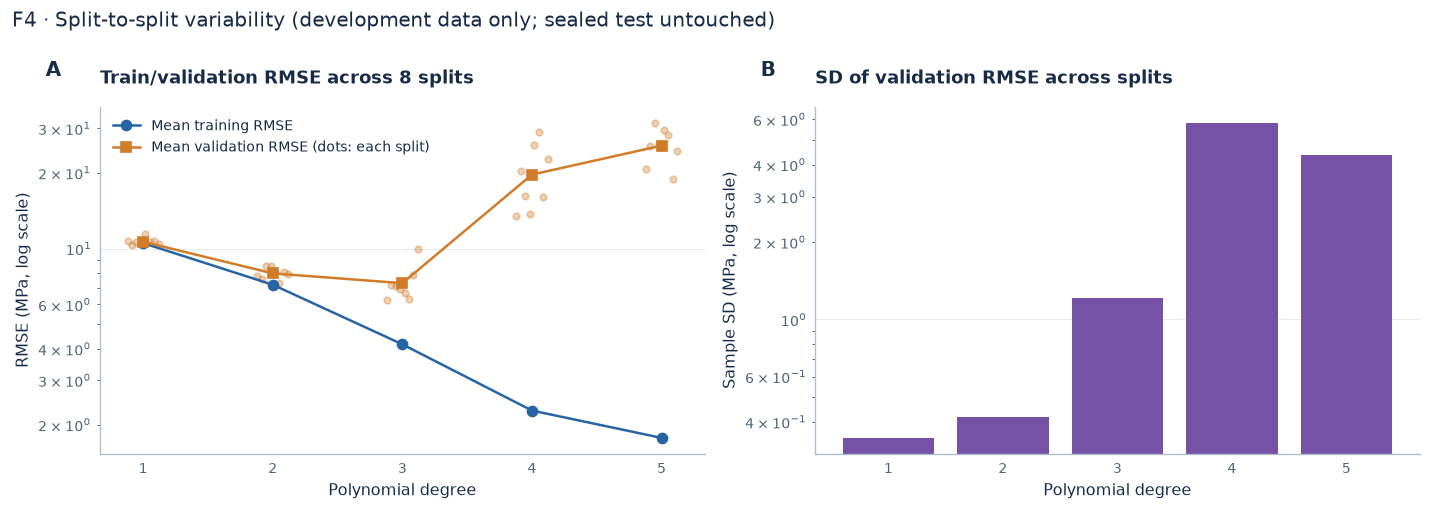

In [6]:
# TASK 4.1 — IMPLEMENT: repeated splits and capacity-versus-variance evidence.
bv = []
for splitseed in range(8):
    fit_idx, val_idx = train_test_split(
        np.arange(len(X_dev)), test_size=0.25, random_state=100 + splitseed
    )
    for degree in [1, 2, 3, 4, 5]:
        res = score(model_ridge(degree, alpha=0.01),
                    X_dev.iloc[fit_idx], y_dev.iloc[fit_idx], X_dev.iloc[val_idx], y_dev.iloc[val_idx])
        bv.append({'splitseed': splitseed, 'degree': degree, **res})

bv = pd.DataFrame(bv)
bv_summary = bv.groupby('degree').agg(mean_train_rmse=('train_rmse', 'mean'),
                                      mean_val_rmse=('val_rmse', 'mean'),
                                      sd_val_rmse=('val_rmse', 'std'),
                                      min_val_rmse=('val_rmse', 'min'),
                                      max_val_rmse=('val_rmse', 'max'))
best_by_split = bv.loc[bv.groupby('splitseed').val_rmse.idxmin(), ['splitseed', 'degree', 'val_rmse']]
print('8 repeated 75/25 splits of the DEVELOPMENT set (RMSE in MPa):')
display(bv_summary.round(3))
print('Best degree per split:', dict(zip(best_by_split.splitseed, best_by_split.degree)))
bv_summary.to_csv(OUT / 'F4_split_summary.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]; panel(ax, 'A', 'Train/validation RMSE across 8 splits')
for dg, g in bv.groupby('degree'):
    ax.scatter(np.full(len(g), dg) + np.linspace(-.12, .12, len(g)), g.val_rmse, color=ORANGE, alpha=.35, s=16)
ax.plot(bv_summary.index, bv_summary.mean_train_rmse, 'o-', color=BLUE, label='Mean training RMSE')
ax.plot(bv_summary.index, bv_summary.mean_val_rmse, 's-', color=ORANGE, label='Mean validation RMSE (dots: each split)')
ax.set_yscale('log'); ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel('Polynomial degree'); ax.set_ylabel('RMSE (MPa, log scale)'); ax.legend()
ax = axes[1]; panel(ax, 'B', 'SD of validation RMSE across splits')
ax.bar(bv_summary.index, bv_summary.sd_val_rmse, color=VIOLET)
ax.set_yscale('log'); ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel('Polynomial degree'); ax.set_ylabel('Sample SD (MPa, log scale)')
fig.suptitle('F4 · Split-to-split variability (development data only; sealed test untouched)', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F4_split_variability')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q5 · Interpreting a gap without confusing risks [13 points]</span>

**(a) [4]** Write $\hat R_n(\theta)$ and $R(\theta)$ and explain which one is *directly* optimized, which one we actually care about, and one assumption needed for validation error to represent deployment.  
**(b) [5]** Diagnose a degree-1 model and degree-5 model in terms of underfitting/overfitting. Use mean training RMSE, mean validation RMSE and spread in **F4**. Carefully distinguish bias and variance from their imperfect proxies.  
**(c) [4]** Why can two random train/validation splits yield different “best degree” decisions even with the same underlying dataset? Would more model capacity solve that uncertainty?

**Answer:**

**(a)** Empirical risk on the $n$ fitting rows: $\hat R_n(\theta)=\frac1n\sum_{i=1}^{n}L\big(y_i,f_\theta(x_i)\big)$. Population risk: $R(\theta)=\mathbb E_{(X,Y)\sim P}\big[L(Y,f_\theta(X))\big]$, the expected loss over future draws from the deployment distribution $P$. Training **directly minimises** $\hat R_n$ (plus any penalty), but we **care about** $R$. $R$ is unknowable because $P$ is unknown, and $\hat R_n(\hat\theta)$ is biased downward because $\hat\theta$ was chosen to make it small. Validation or test error is an unbiased estimate of $R(\hat\theta)$ only if the held-out rows are **independent of the fitting procedure and drawn from the same distribution as deployment** (i.i.d. / no shift). That assumption is questionable here, since recipes repeat across splits and new recipes may differ.

**(b)** **F4 · 8 repeated 75/25 splits of the 824 development rows (RMSE, MPa).**

| Degree | Mean train | Mean val | SD val | Min–max val |
|---:|---:|---:|---:|---|
| 1 | 10.51 | 10.64 | 0.35 | 10.3–11.4 |
| 2 | 7.19 | 7.97 | 0.42 | 7.3–8.5 |
| 3 | 4.17 | **7.29** | 1.21 | 6.3–10.0 |
| 4 | 2.27 | 19.67 | 5.82 | 13.4–29.1 |
| 5 | 1.77 | 25.64 | 4.34 | 18.8–31.7 |

**Degree 1 underfits.** Training and validation RMSE are both high and almost equal (10.5 vs 10.6), and the spread across splits is small (SD 0.35). The error comes from the model being too restrictive — a *bias* symptom — not from sensitivity to the sample. **Degree 5 overfits.** Training RMSE is tiny (1.77) but validation RMSE is 25.6 MPa, worse than the mean baseline, and it varies hugely across splits (18.8–31.7) — a *variance* symptom. Degree 3 balances the two (lowest mean validation RMSE, 7.29). These are **proxies**. The train–validation gap and the split-to-split SD are not the formal bias² and $\operatorname{Var}[\hat f(x)]$: they mix irreducible noise, different validation sets (not just different fits), and overlap between the training sets of the 8 splits, which share rows and are therefore correlated. The formal decomposition is defined pointwise under squared loss over repeated independent training samples, which we do not have.

**(c)** Each split gives a different, finite sample of training and validation rows, so the validation RMSE of each degree is a noisy estimate. When two degrees are close relative to that noise, the ranking can flip — here degree 3 was best on 7 splits and degree 2 on split 7. Degree 3 also has a wider spread (SD 1.21 vs 0.42), so its single-split advantage is less certain. Specific validation rows (e.g. a few extreme old-age or high-strength mixes) can move a high-capacity model's error a lot. **More capacity does not solve this.** It increases sensitivity to the sample (degrees 4–5 have the largest SDs). Selection uncertainty is reduced by more data, by averaging over many folds/repeats (K-fold or repeated CV), and by regularisation — not by a more flexible model.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 4.2 · L1 and L2 are different interventions [12 points]</span>

**Concept lens · Regularization.** Ridge minimizes squared loss **plus** $\lambda\|w\|_2^2$; Lasso adds $\lambda\|w\|_1$. They modify the **training objective**, not the final reported MAE. The intercept is conventionally unpenalized. Larger penalties discourage complex/high-magnitude polynomial coefficients; L1’s nonsmooth geometry can make coefficients **exactly zero**, whereas L2 generally shrinks continuously. Comparison of identical numeric alphas *across* Lasso and Ridge is not intrinsically apples-to-apples, because the penalties have different units/conventions.

**F5/T4:** degree-3 polynomial basis (164 terms); variation in alpha changes validation MAE and coefficient sparsity. `nonzero` uses a displayed tolerance, which is not a proof of mathematical exactness.

**Figure-reading note:** F5B–C show the nine largest coefficient trajectories (by maximum absolute value along each path) for readability. All 164 degree-3 terms were fitted. Alpha scales differ across Ridge and Lasso and are not numerically interchangeable.

**Coding deliverable:** For fixed degree 3, code Ridge/Lasso pipelines, sweep the specified penalty values, extract coefficient vectors, count nonzeros, and plot the separate coefficient paths and validation losses in `F5_regularization`. Export `T4`.

T4 · Degree-3 (164-term) Ridge and Lasso, fit on inner-training, scored on inner-validation (MPa).


,family,alpha,train_MAE,val_MAE,val_RMSE,coefficient_L2,nonzero,nterms
0,Ridge,0.010,3.315,4.729,6.575,114.317,164,164
1,Ridge,0.100,3.330,4.642,6.380,85.874,164,164
2,Ridge,1.000,3.549,4.765,6.195,54.252,164,164
3,Ridge,10.000,4.422,5.547,7.171,23.628,164,164
4,Ridge,100.000,5.606,6.518,8.551,11.464,164,164
5,Lasso,0.001,3.338,4.682,6.506,86.583,154,164
6,Lasso,0.010,3.459,4.741,6.340,72.873,123,164
7,Lasso,0.100,4.471,5.102,6.862,34.832,66,164
8,Lasso,1.000,7.314,7.156,9.347,12.603,18,164
9,Lasso,10.000,13.820,12.843,15.660,0.000,0,164


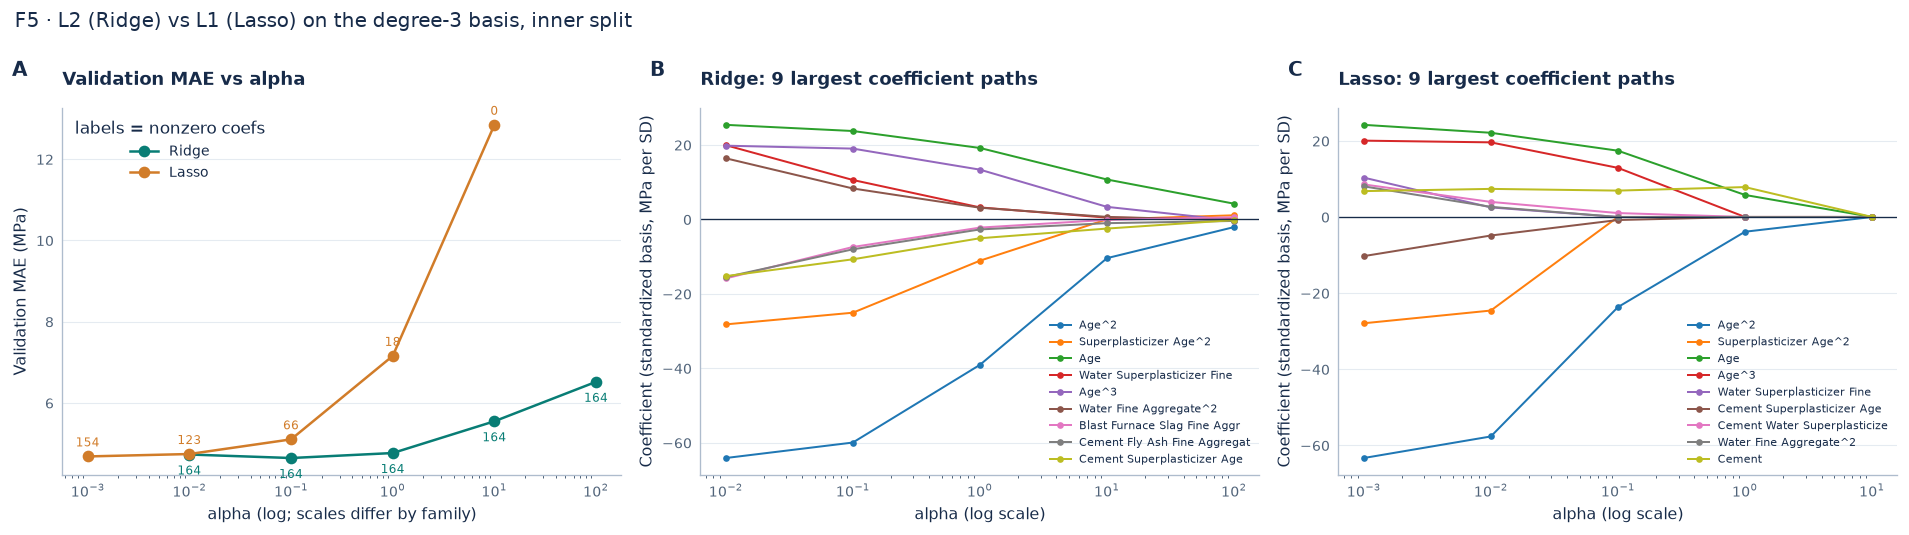

In [7]:
# TASK 4.2 — IMPLEMENT: Ridge/Lasso coefficient paths, sparsity and F5/T4.
# Fit on inner training set ONLY. Use a degree-3 polynomial pipeline.
from sklearn.exceptions import ConvergenceWarning
regrows = []
paths = {}
penalties = {
    'Ridge': [0.01, 0.1, 1, 10, 100],
    'Lasso': [0.001, 0.01, 0.1, 1, 10]
}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for family, alphas in penalties.items():
        for alpha in alphas:
            est = Ridge(alpha=alpha) if family == 'Ridge' else Lasso(alpha=alpha, max_iter=100_000, tol=1e-4)
            pipe = Pipeline([
                ('scale_inputs', StandardScaler()),
                ('poly', PolynomialFeatures(degree=3, include_bias=False)),
                ('scale_expanded', StandardScaler()),
                ('reg', est),
            ]).fit(X_in, y_in)
            coef = pipe.named_steps['reg'].coef_.copy()
            paths[(family, alpha)] = coef
            pv = pipe.predict(X_val)
            regrows.append({'family': family, 'alpha': alpha,
                            'train_MAE': mae(y_in, pipe.predict(X_in)), 'val_MAE': mae(y_val, pv),
                            'val_RMSE': rmse(y_val, pv), 'coefficient_L2': float(np.linalg.norm(coef)),
                            'nonzero': int(np.sum(np.abs(coef) > 1e-4)), 'nterms': len(coef)})

term_names = model_ridge(3).fit(X_in, y_in).named_steps['poly'].get_feature_names_out(feature_names)
T4 = pd.DataFrame(regrows)
T4.to_csv(OUT / 'T4_regularization.csv', index=False)
print('T4 · Degree-3 (164-term) Ridge and Lasso, fit on inner-training, scored on inner-validation (MPa).')
display(T4.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ax = axes[0]; panel(ax, 'A', 'Validation MAE vs alpha')
for fam, col in [('Ridge', TEAL), ('Lasso', ORANGE)]:
    g = T4[T4.family == fam]
    ax.plot(g.alpha, g.val_MAE, 'o-', color=col, label=fam)
    for a, v, nz in zip(g.alpha, g.val_MAE, g.nonzero):
        ax.annotate(f'{nz}', (a, v), textcoords='offset points', xytext=(0, 6 if fam == 'Lasso' else -12), fontsize=7, color=col, ha='center')
ax.set_xscale('log'); ax.set_xlabel('alpha (log; scales differ by family)'); ax.set_ylabel('Validation MAE (MPa)')
ax.legend(title='labels = nonzero coefs')
for ax, fam, col in [(axes[1], 'Ridge', TEAL), (axes[2], 'Lasso', ORANGE)]:
    panel(ax, 'B' if fam == 'Ridge' else 'C', f'{fam}: 9 largest coefficient paths')
    alphas = penalties[fam]
    M = np.vstack([paths[(fam, a)] for a in alphas])
    top = np.argsort(-np.abs(M).max(axis=0))[:9]
    for j in top:
        ax.plot(alphas, M[:, j], 'o-', ms=3, lw=1.2, label=term_names[j][:28])
    ax.axhline(0, color=INK, lw=.8); ax.set_xscale('log')
    ax.set_xlabel('alpha (log scale)'); ax.set_ylabel('Coefficient (standardized basis, MPa per SD)')
    ax.legend(fontsize=6.3, loc='best')
fig.suptitle('F5 · L2 (Ridge) vs L1 (Lasso) on the degree-3 basis, inner split', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F5_regularization')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q6 · Shrinkage, sparsity and interpretability [12 points]</span>

**(a) [5]** Give the OLS, Ridge and Lasso training objectives, stating whether the intercept is penalized and what the regularization parameter does.  
**(b) [4]** Interpret **F5/T4**: how do predictive performance and number of nonzero coefficients change with alpha? Why could an extremely large penalty underfit?  
**(c) [3]** A manager wants a coefficient-based causal explanation of “which ingredient causes stronger concrete.” Explain why a sparse Lasso polynomial model does **not** guarantee causal interpretation.

**Answer:**

**(a)** With features $z_i$ (the standardised degree-3 basis), intercept $b$ and coefficients $w$:
$$\text{OLS: }\min_{b,w}\ \frac1n\sum_i (y_i-b-w^\top z_i)^2$$
$$\text{Ridge: }\min_{b,w}\ \sum_i (y_i-b-w^\top z_i)^2+\alpha\lVert w\rVert_2^2,\qquad \text{Lasso: }\min_{b,w}\ \frac1{2n}\sum_i (y_i-b-w^\top z_i)^2+\alpha\lVert w\rVert_1 .$$
(These are scikit-learn's scalings, which differ by the $1/(2n)$ factor — another reason the α values are not comparable between the two families.) The **intercept is not penalised**: shrinking it would bias predictions toward 0 MPa rather than toward the mean. $\alpha\ge0$ controls the trade-off between fitting the training data and keeping coefficients small. $\alpha=0$ recovers OLS. As $\alpha\to\infty$, all $w\to0$ and the model predicts the training mean. Ridge's smooth L2 penalty shrinks all coefficients proportionally and rarely makes any exactly zero. Lasso's L1 penalty has a corner at 0, so it sets many coefficients **exactly** to zero (feature selection). Standardising the basis matters because the penalty treats all coefficients on the same scale.

**(b)** **T4 · Degree-3 basis (164 terms), fit on inner-training, scored on inner-validation (MPa); nonzero = |coef| > 1e-4.**

| Family | α | Train MAE | Val MAE | Val RMSE | ‖w‖₂ | Nonzero |
|---|---:|---:|---:|---:|---:|---:|
| Ridge | 0.01 | 3.32 | 4.73 | 6.58 | 114.3 | 164 |
| Ridge | 0.1 | 3.33 | **4.64** | 6.38 | 85.9 | 164 |
| Ridge | 1 | 3.55 | 4.77 | 6.20 | 54.3 | 164 |
| Ridge | 10 | 4.42 | 5.55 | 7.17 | 23.6 | 164 |
| Ridge | 100 | 5.61 | 6.52 | 8.55 | 11.5 | 164 |
| Lasso | 0.001 | 3.34 | 4.68 | 6.51 | 86.6 | 154 |
| Lasso | 0.01 | 3.46 | 4.74 | 6.34 | 72.9 | 123 |
| Lasso | 0.1 | 4.47 | 5.10 | 6.86 | 34.8 | 66 |
| Lasso | 1 | 7.31 | 7.16 | 9.35 | 12.6 | 18 |
| Lasso | 10 | 13.82 | 12.84 | 15.66 | 0 | **0** |

For Ridge, validation MAE is flat (4.6–4.8 MPa) for α ≤ 1 and then rises (5.55 at 10, 6.52 at 100). ‖w‖₂ shrinks smoothly (114 → 11), but all 164 coefficients stay nonzero (F5B). For Lasso, small α matches Ridge (4.68 MPa with 154 terms). Increasing α removes terms (123 → 66 → 18 → 0) and validation error rises. At α = 0.01 Lasso keeps 123 of 164 terms at almost the same error, at α = 0.1 it drops to 66 terms for +0.4 MPa, and at α = 10 all coefficients are zero, so it predicts the mean (val MAE 12.84 = the mean baseline). F5C shows coefficients hitting exactly zero one after another, while the Ridge paths approach zero gradually. A very large penalty **underfits**. It forces coefficients toward zero regardless of the data, so the model cannot represent the real dependence of strength on age and ingredients: bias rises, and training and validation error both rise together (Lasso α = 1: 7.31 / 7.16 MPa).

**(c)** Sparsity is a statement about **prediction**, not causation. (1) The basis terms are polynomial products of correlated ingredients. When terms are correlated, Lasso picks one of them more or less arbitrarily, and which one survives can change with α or with the sample. A zero coefficient does not mean the ingredient has no effect, and a nonzero term (e.g. Water·Superplasticizer·Fine Aggregate) is not a separate physical mechanism. (2) The data are observational, so confounding is possible. Mixes are designed with coupled quantities (e.g. high-strength mixes use more superplasticizer *and* less water), and coefficients absorb these design correlations. (3) The penalty deliberately biases the coefficients toward zero, and the selected model is tuned for validation error, not for unbiased effect estimates. A causal claim about "which ingredient causes stronger concrete" requires controlled experiments (varying one ingredient while holding the rest fixed) or an explicit causal model with domain knowledge, plus confidence intervals — not a sparse predictive fit.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 4.3 · Early stopping without an explicit penalty [10 points]</span>

**Concept lens · The optimizer can overfit too.** Gradient descent changes coefficients iteratively to reduce training loss. If the model is highly flexible and labels are noisy, later steps can fit idiosyncrasies of the training sample. **Early stopping** chooses a checkpoint using a separate clean validation set. It restricts the effective fitted solution *without explicitly adding* L1 or L2 to the objective.

**F6 is deliberately a stress test:** 100 inner-fitting records, degree 4, 20% **synthetically corrupted fitting labels**, clean validation, no final-test access. We evaluate exact full-batch GD checkpoints using an eigendecomposition for efficiency (the same iterates as gradient descent on the stated quadratic objective). It is **not** evidence that real UCI measurements are wrong. The training curve is evaluated on the corrupted labels; the validation curve on clean labels. The optimal stopping point need not be identical in every possible dataset.

**Coding deliverable:** The 100-row subsample, 20% artificial label corruption, preprocessing, and stable spectral checkpoint setup are **supplied boilerplate** because those are not the learning objective. You must implement the checkpoint predictions and train/validation MAE trace, choose the best checkpoint, and plot/annotate `F6_early_stopping`. The report must explain the full-batch GD update and why stopping differs from a weight penalty.

F6 early stopping (SYNTHETIC: 20/100 fitting labels shifted by ±32.42 MPa; degree 4, 494 terms; step size 0.008383)
Best clean-validation checkpoint: epoch 11, val MAE 8.144 MPa, train MAE (corrupted) 10.575 MPa
Last checkpoint: epoch 100000, val MAE 35.551 MPa, train MAE (corrupted) 0.760 MPa
First checkpoint: epoch 1, val MAE 11.020 MPa



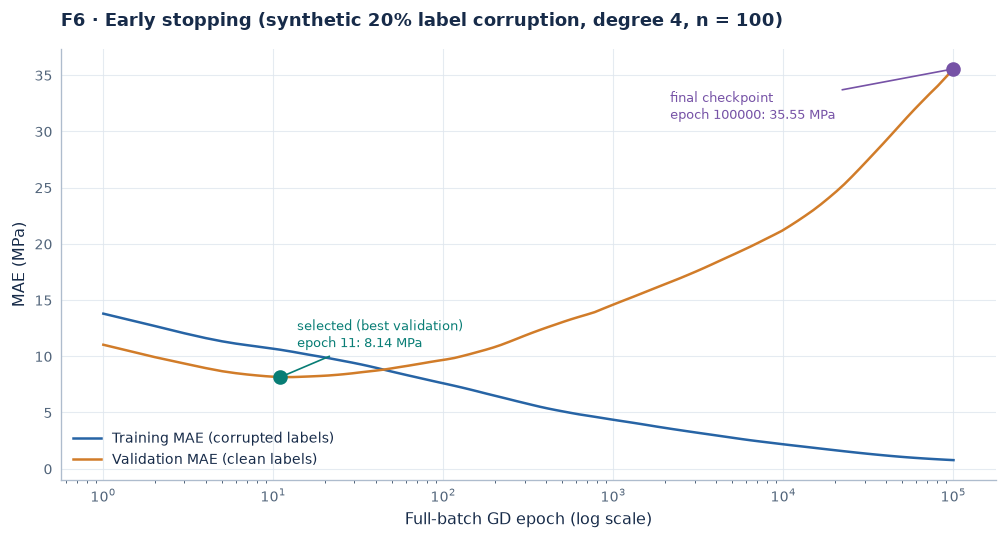

In [8]:
# TASK 4.3 — IMPLEMENT: reproducible early-stopping stress test.
# BOILERPLATE: sample and corrupt 100 INNER-TRAINING observations ONLY.
# The original UCI test set is untouched. This is controlled SYNTHETIC noise.
rng_subset = np.random.default_rng(81)
ids = rng_subset.choice(len(X_in), size=100, replace=False)
xt = X_in.iloc[ids].to_numpy()
yt_clean = y_in.iloc[ids].to_numpy(dtype=float)
xv = X_val.to_numpy()
yv = y_val.to_numpy(dtype=float)
rng_noise = np.random.default_rng(2027)
yt_noisy = yt_clean.copy()
corrupted_ids = rng_noise.choice(len(yt_noisy), size=20, replace=False)
shock_signs = rng_noise.choice([-1.0, 1.0], size=len(corrupted_ids))
shock_mpa = 2.0 * float(np.std(yt_clean))
yt_noisy[corrupted_ids] += shock_signs * shock_mpa

# BOILERPLATE: safe polynomial preprocessing, fitted on the 100 fitting rows.
pre_f6 = Pipeline([
    ('input_minmax', MinMaxScaler()),
    ('poly', PolynomialFeatures(degree=4, include_bias=False)),
    ('poly_standardize', StandardScaler()),
])
Ztr = np.asarray(pre_f6.fit_transform(xt), dtype=float)
Zval = np.asarray(pre_f6.transform(xv), dtype=float)
y_center = float(yt_noisy.mean())
y_scale = max(float(yt_noisy.std()), 1e-12)
y_scaled = (yt_noisy - y_center) / y_scale
n_small = len(yt_noisy)

# BOILERPLATE: use a spectrum of the sample-space Gram matrix to efficiently
# evaluate full-batch GD at long-run checkpoints, rather than 100,000 Python loops.
# The objective is (1/2n)||Ztr w - y_scaled||² with initial w=0.
Ktr = Ztr @ Ztr.T / n_small
Kval = Zval @ Ztr.T / n_small
lam, U = np.linalg.eigh(Ktr)
lam = np.maximum(lam, 0.0)
step_size = 0.85 / max(float(lam.max()), 1e-12)
uy = U.T @ y_scaled
log_base = np.log1p(-step_size * lam)
checkpoints = np.unique(np.rint(np.geomspace(1, 100_000, 110)).astype(int))

trace = []
safe = lam > 1e-10
for epoch in checkpoints:
    gain = -np.expm1(epoch * log_base)                       # 1 - (1 - eta*lam)^epoch
    gain_over_lam = np.where(safe, gain / np.where(safe, lam, 1.0), epoch * step_size)
    fitted_train = y_center + y_scale * U @ (gain * uy)
    fitted_val = y_center + y_scale * Kval @ U @ (gain_over_lam * uy)
    trace.append({'epoch': int(epoch),
                  'train_MAE_corrupted_MPa': mae(yt_noisy, fitted_train),
                  'train_MAE_clean_labels_MPa': mae(yt_clean, fitted_train),
                  'validation_MAE_clean_MPa': mae(yv, fitted_val)})

es = pd.DataFrame(trace)
best_row = es.loc[es.validation_MAE_clean_MPa.idxmin()]
last_row = es.iloc[-1]
es.to_csv(OUT / 'F6_early_stopping_trace.csv', index=False)
summary = (f"F6 early stopping (SYNTHETIC: 20/100 fitting labels shifted by ±{shock_mpa:.2f} MPa; degree 4, "
           f"{Ztr.shape[1]} terms; step size {step_size:.4g})\n"
           f"Best clean-validation checkpoint: epoch {int(best_row.epoch)}, val MAE {best_row.validation_MAE_clean_MPa:.3f} MPa, "
           f"train MAE (corrupted) {best_row.train_MAE_corrupted_MPa:.3f} MPa\n"
           f"Last checkpoint: epoch {int(last_row.epoch)}, val MAE {last_row.validation_MAE_clean_MPa:.3f} MPa, "
           f"train MAE (corrupted) {last_row.train_MAE_corrupted_MPa:.3f} MPa\n"
           f"First checkpoint: epoch {int(es.epoch.iloc[0])}, val MAE {es.validation_MAE_clean_MPa.iloc[0]:.3f} MPa\n")
(OUT / 'F6_checkpoint_summary.txt').write_text(summary)
print(summary)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
panel(ax, '', 'F6 · Early stopping (synthetic 20% label corruption, degree 4, n = 100)', grid_axis='both')
ax.plot(es.epoch, es.train_MAE_corrupted_MPa, color=BLUE, label='Training MAE (corrupted labels)')
ax.plot(es.epoch, es.validation_MAE_clean_MPa, color=ORANGE, label='Validation MAE (clean labels)')
for row, lab, col in [(best_row, 'selected (best validation)', TEAL), (last_row, 'final checkpoint', VIOLET)]:
    ax.scatter([row.epoch], [row.validation_MAE_clean_MPa], color=col, s=60, zorder=5)
    ax.annotate(f'{lab}\nepoch {int(row.epoch)}: {row.validation_MAE_clean_MPa:.2f} MPa',
                (row.epoch, row.validation_MAE_clean_MPa), textcoords='offset points',
                xytext=(-170, -30) if row is last_row else (10, 18), fontsize=8, color=col,
                arrowprops=dict(arrowstyle='-', color=col))
ax.set_xscale('log'); ax.set_xlabel('Full-batch GD epoch (log scale)'); ax.set_ylabel('MAE (MPa)')
ax.legend(loc='lower left')
fig.tight_layout()
save_figure(fig, 'F6_early_stopping')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q7 · Why not just finish training? [10 points]</span>

**(a) [3]** Give the batch-GD update for least-squares regression and state the role of the learning rate.  
**(b) [4]** From **F6** report best epoch, last epoch, clean-validation MAE at both, and training MAE behavior. Explain why the *earlier* checkpoint can generalize better despite worse fitting-loss.  
**(c) [3]** Contrast early stopping with L1/L2 regularization, and explain why choosing the epoch by **final test MAE** would invalidate the final-test estimate.

**Answer:**

**(a)** For the scaled least-squares objective $J(w)=\frac1{2n}\lVert Zw-y\rVert^2$ (intercept handled by centring $y$), the full-batch gradient-descent update is
$$w^{(t+1)}=w^{(t)}-\eta\,\nabla J(w^{(t)})=w^{(t)}-\frac{\eta}{n}Z^\top\big(Zw^{(t)}-y\big),\qquad w^{(0)}=0 .$$
The **learning rate** $\eta$ sets the step size. It must satisfy $\eta<2/\lambda_{\max}(Z^\top Z/n)$ for convergence (here $\eta=0.85/\lambda_{\max}=0.0084$). Too large diverges or oscillates; too small makes progress slow. Along each eigendirection of $Z^\top Z/n$ with eigenvalue $\lambda_k$, the fitted component after $t$ steps is a fraction $1-(1-\eta\lambda_k)^t$ of its least-squares value. Large-eigenvalue (well-determined) directions are fitted first, and small-eigenvalue (noise-dominated) directions only after many epochs.

**(b)** (**SYNTHETIC stress test:** 100 inner-training rows, 20 of them shifted by ±32.4 MPa; degree 4 = 494 terms > 100 rows; validation labels clean.) **Best checkpoint: epoch 11**, clean-validation MAE **8.14 MPa** (training MAE on corrupted labels 10.58 MPa). **Last checkpoint: epoch 100,000**, clean-validation MAE **35.55 MPa**, while training MAE falls to **0.76 MPa**. Training MAE decreases monotonically over the whole run. Validation MAE falls from 11.0 MPa (epoch 1) to its minimum at about epoch 11, then rises steadily (F6). The curves cross near epoch 40. With 494 terms and 100 rows, continued GD keeps fitting smaller-eigenvalue directions until it nearly interpolates the training labels, *including* the 20 corrupted ones, and wild high-order terms are needed to do so. The early checkpoint has captured the dominant, well-determined structure (mainly age and cement effects) but has not yet fitted the noise. Its worse training loss reflects *refusing to fit corrupted labels*, which is why it generalises better.

**(c)** Early stopping regularises **implicitly**. The objective is unchanged; the optimisation trajectory is truncated, which restricts how far $w$ can move from 0, and the number of epochs acts as the hyperparameter. For least squares, stopping after $t$ steps behaves much like Ridge with $\alpha\approx 1/(\eta t)$: the gains $1-(1-\eta\lambda)^t$ resemble Ridge's $\lambda/(\lambda+\alpha)$. **L2/L1** regularisation instead **change the objective** by adding $\alpha\lVert w\rVert_2^2$ or $\alpha\lVert w\rVert_1$, so their solution is a well-defined optimum that does not depend on the optimiser or the starting point. L1 additionally produces exact zeros, which early stopping does not. Choosing the epoch by **final test MAE** would make the test set part of model selection. The reported test MAE would then be the minimum over 110 checkpoints, an optimistically biased estimate, rather than an independent estimate of performance on new data. The epoch must be chosen on validation data, and the test set used once.

<span style="color:#6941C6; font-size:21px; font-weight:700;">Task 4.4 · Five-fold CV and the “new recipe” trap [15 points]</span>

**Concept lens · Model selection is not model evaluation.** In 5-fold CV, each candidate $(\mathrm{degree},\alpha)$ is trained on four folds and validated on the fifth, repeating five times. The **entire preprocessing pipeline** fits inside each training fold. The mean validation MAE selects hyperparameters; `GridSearchCV(refit=True)` then refits the chosen pipeline on the whole development partition. Only after that do we **open the final sealed test once**.

**Counterfactual deployment:** Row-wise random folds may put identical recipes at multiple ages in train and validation. **GroupKFold**, grouping by the seven ingredient quantities (ignoring age), measures a harder *new-exact-recipe* scenario. We compare CV estimates before final testing; this is a **sensitivity check**, not an extra round of test-set tuning.

**F7** plots the CV grid. **F8** shows the sealed-test residuals and recipe-based cross-validation contrast.

**Figure-reading note:** F7 reports selected-hyperparameter scores from five folds. Individual fold values are *descriptive* and should not be presented as five independent experiments. F8C measures the fraction of sealed-test predictions within a chosen absolute-error tolerance.

**Coding deliverable:** Build and run your own `GridSearchCV` on **development data only** with 5 folds and the stated degree/alpha grid. All scaling must remain in a pipeline inside CV. Produce `F7_cv_heatmap` and the detailed CSV of CV results.

Selected: degree = 3, alpha = 1, mean 5-fold CV MAE = 4.753 MPa


,param_poly__degree,param_reg__alpha,mean_train_MAE,mean_val_MAE,sd_val_MAE,rank_test_score,fold0_val_MAE,fold1_val_MAE,fold2_val_MAE,fold3_val_MAE,fold4_val_MAE
9,3,1.0,3.531,4.753,0.441,1,4.390,5.525,4.546,4.954,4.353
8,3,0.1,3.319,4.854,0.560,2,4.546,5.736,4.346,5.287,4.357
14,4,10.0,3.392,5.214,0.287,3,4.957,5.721,5.116,5.323,4.953
13,4,1.0,2.587,5.313,0.507,4,5.005,5.551,5.753,5.788,4.467
10,3,10.0,4.413,5.523,0.499,5,5.040,6.489,5.386,5.355,5.346
15,4,100.0,4.802,6.036,0.437,6,5.589,6.867,5.827,6.006,5.892
5,2,1.0,5.532,6.056,0.462,7,5.671,6.872,5.936,6.210,5.591
4,2,0.1,5.526,6.058,0.454,8,5.691,6.869,5.958,6.180,5.594


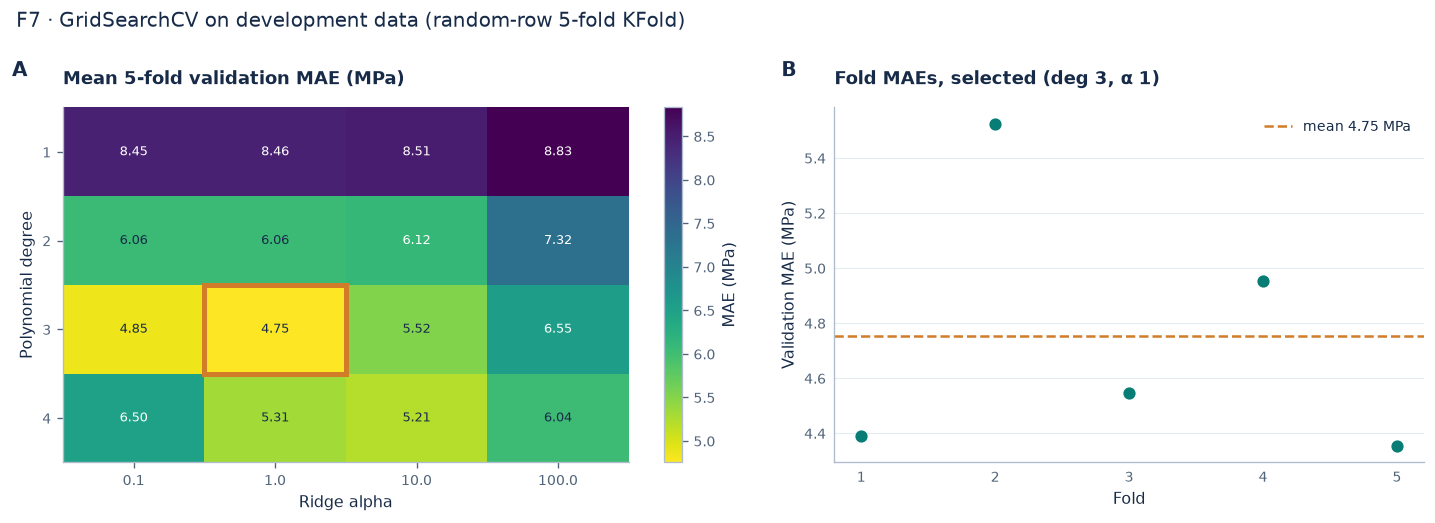

In [9]:
# TASK 4.4 — IMPLEMENT: five-fold CV for polynomial Ridge.
# IMPORTANT: all transformations go INSIDE the pipeline passed to GridSearchCV.
cv = KFold(n_splits=5, shuffle=True, random_state=101)
param_grid = {
    'poly__degree': [1, 2, 3, 4],
    'reg__alpha': [0.1, 1, 10, 100]
}
cv_pipe = Pipeline([
    ('scale_inputs', StandardScaler()),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scale_expanded', StandardScaler()),
    ('reg', Ridge()),
])
grid = GridSearchCV(cv_pipe, param_grid, scoring='neg_mean_absolute_error', cv=cv,
                    return_train_score=True, refit=True)
grid.fit(X_dev, y_dev)

res = pd.DataFrame(grid.cv_results_)
res['mean_val_MAE'] = -res.mean_test_score
res['sd_val_MAE'] = res.std_test_score
res['mean_train_MAE'] = -res.mean_train_score
fold_cols = [f'split{i}_test_score' for i in range(5)]
for i, c in enumerate(fold_cols):
    res[f'fold{i}_val_MAE'] = -res[c]
cv_details = res[['param_poly__degree', 'param_reg__alpha', 'mean_train_MAE', 'mean_val_MAE', 'sd_val_MAE', 'rank_test_score']
                 + [f'fold{i}_val_MAE' for i in range(5)]].sort_values('rank_test_score')
cv_details.to_csv(OUT / 'CV_grid_details.csv', index=False)
best_degree, best_alpha = grid.best_params_['poly__degree'], grid.best_params_['reg__alpha']
best_cv_mae = -grid.best_score_
print(f'Selected: degree = {best_degree}, alpha = {best_alpha}, mean 5-fold CV MAE = {best_cv_mae:.3f} MPa')
display(cv_details.head(8).round(3))

heat = res.pivot(index='param_poly__degree', columns='param_reg__alpha', values='mean_val_MAE')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'width_ratios': [1.2, 1]})
ax = axes[0]
ax.text(-0.09, 1.075, 'A', transform=ax.transAxes, fontsize=12, fontweight='bold', color=INK, va='bottom')
ax.set_title('Mean 5-fold validation MAE (MPa)', loc='left', pad=14)
im = ax.imshow(heat.values, cmap='viridis_r', aspect='auto')
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
ax.set_xlabel('Ridge alpha'); ax.set_ylabel('Polynomial degree')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if v > np.nanmedian(heat.values) else INK)
bi, bj = list(heat.index).index(best_degree), list(heat.columns).index(best_alpha)
ax.add_patch(Rectangle((bj - .5, bi - .5), 1, 1, fill=False, ec=ORANGE, lw=3))
fig.colorbar(im, ax=ax, label='MAE (MPa)')
ax = axes[1]; panel(ax, 'B', f'Fold MAEs, selected (deg {best_degree}, α {best_alpha})')
best_row = res.loc[grid.best_index_]
folds = [best_row[f'fold{i}_val_MAE'] for i in range(5)]
ax.scatter(range(1, 6), folds, color=TEAL, s=40, zorder=3)
ax.axhline(np.mean(folds), color=ORANGE, ls='--', label=f'mean {np.mean(folds):.2f} MPa')
ax.set_xticks(range(1, 6)); ax.set_xlabel('Fold'); ax.set_ylabel('Validation MAE (MPa)'); ax.legend()
fig.suptitle('F7 · GridSearchCV on development data (random-row 5-fold KFold)', x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F7_cv_heatmap')

**New recipe audit.** The group identifier below uses the exact **seven ingredient coordinates** (excluding cure age), not a vague label such as “same type of concrete.” It is a proxy for deployment, not a definitive batch identifier. Never use `X_test` here.

**Coding deliverable:** Derive recipe groups from ingredient columns and implement a `GroupKFold` audit against random-row `KFold` using the **same already-selected model**. This audit is not another hyperparameter search.

In [10]:
# TASK 4.4 — IMPLEMENT: grouped cross-validation audit for new recipes.
# Use EXACT seven-ingredient coordinates (exclude curing age) for groups.
recipe_groups = pd.util.hash_pandas_object(X_dev.iloc[:, :7], index=False).to_numpy()
from sklearn.base import clone
sel_degree, sel_alpha = grid.best_params_['poly__degree'], grid.best_params_['reg__alpha']
selected_spec = model_ridge(sel_degree, alpha=sel_alpha)       # same selected configuration, refit per fold

random_scores = -cross_val_score(clone(selected_spec), X_dev, y_dev, scoring='neg_mean_absolute_error',
                                 cv=KFold(n_splits=5, shuffle=True, random_state=101))
group_scores = -cross_val_score(clone(selected_spec), X_dev, y_dev, scoring='neg_mean_absolute_error',
                                cv=GroupKFold(n_splits=5), groups=recipe_groups)

n_recipes = len(np.unique(recipe_groups))
print(f'Development rows: {len(X_dev)}; unique 7-ingredient recipes: {n_recipes} '
      f'(mean {len(X_dev)/n_recipes:.2f} rows per recipe)')
recipe_cv = pd.DataFrame({
    'mean_MAE_MPa': [random_scores.mean(), group_scores.mean()],
    'sd_MAE_MPa': [random_scores.std(ddof=1), group_scores.std(ddof=1)],
    'folds': [np.round(random_scores, 2), np.round(group_scores, 2)],
}, index=['Random-row KFold (5)', 'Recipe GroupKFold (5)'])
display(recipe_cv)
print(f'Grouped minus random mean MAE: {group_scores.mean() - random_scores.mean():+.3f} MPa '
      f'({100*(group_scores.mean()/random_scores.mean()-1):+.1f}%)')

Development rows: 824; unique 7-ingredient recipes: 373 (mean 2.21 rows per recipe)


,mean_MAE_MPa,sd_MAE_MPa,folds
Random-row KFold (5),4.753313,0.492689,"[4.39, 5.52, 4.55, 4.95, 4.35]"
Recipe GroupKFold (5),5.433579,0.756253,"[5.48, 4.63, 6.66, 5.32, 5.07]"


Grouped minus random mean MAE: +0.680 MPa (+14.3%)


**The final test set is now unsealed.** The next cell is the **only** place where final test labels are used to compute metrics. Do **not** rerun tuning based on what it prints.

**Coding deliverable:** Evaluate the selected estimator on the sealed test once; code `F8_final_test` (prediction scatter, residuals, tolerance curve) and `F8b_recipe_cv` (random vs grouped-fold errors). Preserve all test-set discipline. Submit only interpretations and figures in the PDF.

Selected hyperparameters: degree=3, alpha=1
Mean 5-fold CV MAE (development): 4.753 MPa
Sealed test (n=206): MAE=5.004 MPa, RMSE=7.099 MPa, R2=0.804, signed error (ŷ−y)=+0.072 MPa
Share within ±2 MPa: 27.2%
Share within ±5 MPa: 65.5%
Share within ±10 MPa: 90.3%
Share within ±15 MPa: 96.6%
Random-row CV MAE 4.753 ± 0.493; recipe-group CV MAE 5.434 ± 0.756 MPa

Share of test predictions within ±5 MPa: 65.5%


,age_slice,n,MAE_MPa,CI95_low,CI95_high,signed_error_MPa,pct_within_5MPa
0,≤28 days,147,5.27,4.45,6.20,-0.58,61.90
1,29–90 days,29,3.19,2.50,3.95,0.66,86.21
2,>90 days,30,5.44,3.84,7.35,2.71,63.33


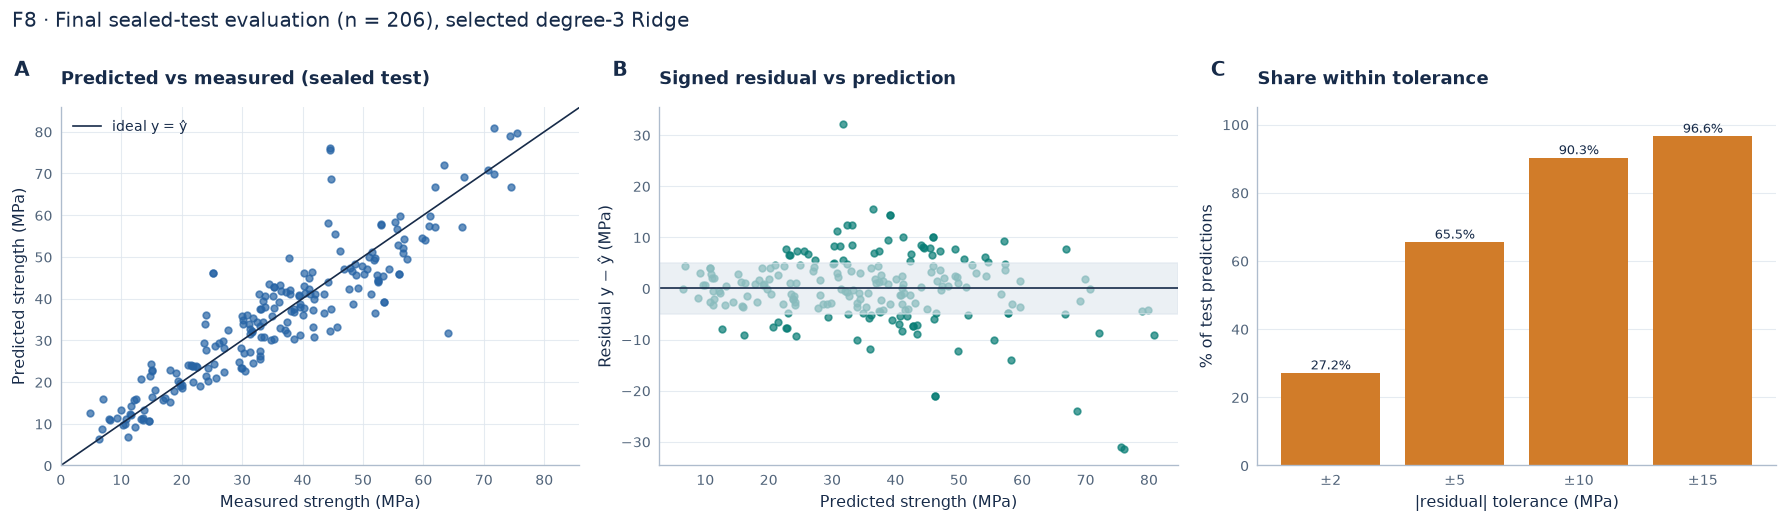

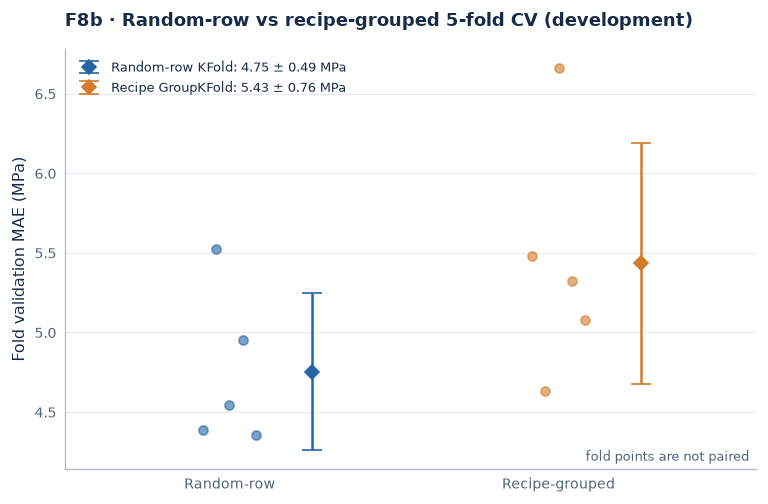

In [11]:
# TASK 4.4 — IMPLEMENT: ONE final test evaluation and final figures.
# DO NOT open y_test to tune, select, or modify any hyperparameters.
selected = grid.best_estimator_  # fitted on all development observations
test_pred = selected.predict(X_test)
test_resid = y_test.to_numpy() - test_pred
final_mae = mae(y_test, test_pred)
final_rmse = rmse(y_test, test_pred)
final_r2 = float(r2_score(y_test, test_pred))
signed_bias = float(np.mean(test_pred - y_test.to_numpy()))
tols = [2, 5, 10, 15]
within = {t: float(100 * np.mean(np.abs(test_resid) <= t)) for t in tols}

test_age = X_test['Age'].to_numpy()
age_rows = []
for name, mask in [('≤28 days', test_age <= 28), ('29–90 days', (test_age > 28) & (test_age <= 90)),
                   ('>90 days', test_age > 90)]:
    lo, hi = mean_ci(np.abs(test_resid[mask]))
    age_rows.append({'age_slice': name, 'n': int(mask.sum()), 'MAE_MPa': np.abs(test_resid[mask]).mean(),
                     'CI95_low': lo, 'CI95_high': hi,
                     'signed_error_MPa': float(np.mean(-test_resid[mask])),
                     'pct_within_5MPa': 100 * np.mean(np.abs(test_resid[mask]) <= 5)})
test_age_table = pd.DataFrame(age_rows)

summary = (f"Selected hyperparameters: degree={grid.best_params_['poly__degree']}, alpha={grid.best_params_['reg__alpha']}\n"
           f"Mean 5-fold CV MAE (development): {-grid.best_score_:.3f} MPa\n"
           f"Sealed test (n={len(y_test)}): MAE={final_mae:.3f} MPa, RMSE={final_rmse:.3f} MPa, R2={final_r2:.3f}, "
           f"signed error (ŷ−y)={signed_bias:+.3f} MPa\n"
           + ''.join(f'Share within ±{t} MPa: {v:.1f}%\n' for t, v in within.items())
           + f"Random-row CV MAE {random_scores.mean():.3f} ± {random_scores.std(ddof=1):.3f}; "
             f"recipe-group CV MAE {group_scores.mean():.3f} ± {group_scores.std(ddof=1):.3f} MPa\n")
(OUT / 'final_test_summary.txt').write_text(summary + '\n' + test_age_table.round(3).to_string(index=False))
print(summary)
print(f'Share of test predictions within ±5 MPa: {within[5]:.1f}%')
display(test_age_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]; panel(ax, 'A', 'Predicted vs measured (sealed test)', grid_axis='both')
ax.scatter(y_test, test_pred, s=16, alpha=.7, color=BLUE)
lim = [0, max(y_test.max(), test_pred.max()) + 5]
ax.plot(lim, lim, color=INK, lw=1, label='ideal y = ŷ'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Measured strength (MPa)'); ax.set_ylabel('Predicted strength (MPa)'); ax.legend()
ax = axes[1]; panel(ax, 'B', 'Signed residual vs prediction')
ax.scatter(test_pred, test_resid, s=16, alpha=.7, color=TEAL)
ax.axhline(0, color=INK, lw=1); ax.axhspan(-5, 5, color=GRID, alpha=.6)
ax.set_xlabel('Predicted strength (MPa)'); ax.set_ylabel('Residual y − ŷ (MPa)')
ax = axes[2]; panel(ax, 'C', 'Share within tolerance')
ax.bar([f'±{t}' for t in tols], [within[t] for t in tols], color=ORANGE)
for i, t in enumerate(tols): ax.text(i, within[t] + 1, f'{within[t]:.1f}%', ha='center', fontsize=8)
ax.set_ylim(0, 105); ax.set_xlabel('|residual| tolerance (MPa)'); ax.set_ylabel('% of test predictions')
fig.suptitle(f'F8 · Final sealed-test evaluation (n = {len(y_test)}), selected degree-{grid.best_params_["poly__degree"]} Ridge',
             x=.01, ha='left')
fig.tight_layout()
save_figure(fig, 'F8_final_test')

fig, ax = plt.subplots(figsize=(6.5, 4.3))
panel(ax, '', 'F8b · Random-row vs recipe-grouped 5-fold CV (development)')
for i, (lab, s, col) in enumerate([('Random-row KFold', random_scores, BLUE), ('Recipe GroupKFold', group_scores, ORANGE)]):
    ax.scatter(np.full(5, i) + np.linspace(-.08, .08, 5), s, color=col, alpha=.6, s=30)
    ax.errorbar(i + .25, s.mean(), yerr=s.std(ddof=1), fmt='D', color=col, capsize=6,
                label=f'{lab}: {s.mean():.2f} ± {s.std(ddof=1):.2f} MPa')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Random-row', 'Recipe-grouped']); ax.set_xlim(-.5, 1.6)
ax.set_ylabel('Fold validation MAE (MPa)'); ax.legend(fontsize=7.5, loc='upper left')
ax.text(.99, .02, 'fold points are not paired', transform=ax.transAxes, ha='right', fontsize=7.5, color=MUTED)
fig.tight_layout()
save_figure(fig, 'F8b_recipe_cv')

<span style="color:#16845B; font-size:19px; font-weight:700;">Question Q8 · Defend the selected model and evaluation protocol [15 points]</span>

**(a) [5]** Write a precise five-fold CV algorithm: for each candidate, name which rows fit `StandardScaler`, `PolynomialFeatures`, the second `StandardScaler`, and Ridge. State what **data leakage** would look like.  
**(b) [4]** Report the chosen degree/alpha, mean CV MAE, **final test MAE/RMSE**, signed error, and the percentage of test predictions within ±5 MPa (F8C). Why can the final score differ from the CV score? Why is repeatedly changing hyperparameters based on the test score methodologically wrong?  
**(c) [3]** Compare random-row and grouped-recipe CV. What question does each estimate, and what happens to your confidence about deployment on previously unseen recipes? If grouped performance is not worse, does that prove no deployment shift exists?  
**(d) [3]** Include a **Regression Model Card** for your final CV-selected model. Use the concise format described in the assignment guide: model overview/intended use, dataset and features, training and validation protocol, quantitative performance (overall and by curing-age slice), key limitations, inappropriate use, and required monitoring/additional testing. End with a defensible deployment recommendation. Do not invent unavailable subgroup evidence.

**Answer:**

**(a)** Five-fold CV for each candidate $(d,\alpha)$ in {1,2,3,4} × {0.1,1,10,100}, on the 824 development rows only (the 206 test rows are never touched):
1. Shuffle the development indices (`KFold(5, shuffle=True, random_state=101)`) and split them into folds $F_1,\dots,F_5$.
2. For each fold $k$: let $T_k=\text{dev}\setminus F_k$ be the training rows.
   (i) Fit the first `StandardScaler` (input means and SDs) on $T_k$ only.
   (ii) Apply `PolynomialFeatures(d)`, a fixed transform with no learned parameters, to the scaled $T_k$ rows.
   (iii) Fit the second `StandardScaler` (means and SDs of the expanded terms) on $T_k$ only.
   (iv) Fit `Ridge(α)` on $T_k$ only.
   (v) Pass $F_k$ through the *already fitted* transforms and compute its MAE.
3. Average the five fold MAEs. Choose the $(d,\alpha)$ with the lowest mean (`GridSearchCV`).
4. Refit the full pipeline on all 824 development rows (`refit=True`), then evaluate it **once** on the sealed test set.

**Leakage** would mean any information from the validation fold, or from the test set, reaching the fitting steps. Examples: fitting either scaler on all 824 rows (or on dev + test) before CV; choosing the degree from a pre-CV look at all the data; recipe duplicates whose labels effectively appear in both training and validation; or re-running the search after seeing the test score.

**(b)** **Selected: degree 3, α = 1. Mean 5-fold CV MAE = 4.75 MPa** (fold MAEs 4.39–5.52, F7; runner-up degree 3, α = 0.1, 4.85). **Sealed test (n = 206): MAE 5.00 MPa, RMSE 7.10 MPa, R² 0.804, signed error (ŷ−y) +0.07 MPa, 65.5% of predictions within ±5 MPa** (27.2% within ±2, 90.3% within ±10, 96.6% within ±15; F8C). The test MAE is 0.25 MPa above CV for several reasons: CV is an estimate with its own noise (fold SD ≈ 0.49 MPa); the test is one random sample of 206 rows; the selected configuration is the *minimum* of 16 noisy CV means, so its CV score is slightly optimistic (winner's curse); and the test set contains a few hard high-strength and old-age points (F8A/B). Changing hyperparameters after seeing the test score turns the test set into a validation set. Each change uses test labels to select the model, so the final number is no longer an unbiased estimate of performance on new data, and nothing is left to check against. Further tuning would require a new, untouched test set.

**(c)** **Random-row KFold** (same selected model, refit per fold): MAE **4.75 ± 0.49 MPa**. **Recipe-grouped GroupKFold** (373 unique recipes, so no recipe appears in both training and validation): **5.43 ± 0.76 MPa**, which is **+0.68 MPa (+14%)** worse (F8b). Random-row CV estimates error on *new specimens of mostly known recipes*: the same recipe at other ages is usually in training, so the model partly interpolates along age. Grouped CV estimates error on *recipes never tested before*, the laboratory's actual question. My confidence for unseen recipes is therefore lower. The ≈5.0 MPa test MAE comes from a random-row test set, so it inherits the optimism of the random-row design, and ≈5.4 MPa (or worse) is the more honest new-recipe estimate. Even if grouped CV had not been worse, that would not prove there is no deployment shift. Grouping only removes *exact* recipe matches: near-identical recipes remain on both sides. All folds still come from the same historical data sources, materials and ingredient ranges. Future mixes can use new suppliers, admixtures, curing regimes or proportions outside the observed ranges, and none of this can be tested with the existing data.

**(d) Regression Model Card**

| Field | Content |
|---|---|
| **Model overview** | Degree-3 polynomial Ridge regression (α = 1): `StandardScaler → PolynomialFeatures(3) (164 terms) → StandardScaler → Ridge`. Output: predicted compressive strength (MPa) of a given mix at a given curing age. Intended decision: **prioritise and schedule** laboratory crushing tests and screen candidate recipes. It is *not* an acceptance or safety decision. |
| **Data** | UCI Concrete Compressive Strength (Yeh 1998; DOI 10.24432/C5PK67; CC BY 4.0). 1,030 mix-at-age rows: 7 ingredients (kg/m³) + Age (1–365 days) → strength (MPa, 2.3–82.6). 824 development rows (373 unique recipes) and 206 sealed test rows. No missing values. All preprocessing is fitted inside the pipeline on training folds only. |
| **Training & validation protocol** | 5-fold shuffled KFold `GridSearchCV` over degree {1–4} × α {0.1, 1, 10, 100} on development data, selected by mean MAE, then refit on all development data. Sensitivity check: GroupKFold by exact recipe. The test set was evaluated once, after selection. |
| **Performance** | CV MAE 4.75 MPa (random rows) vs **5.43 MPa (new recipes)**. Sealed test: **MAE 5.00 MPa, RMSE 7.10 MPa**, R² 0.80, signed error +0.07 MPa, 65.5% within ±5 MPa, 90.3% within ±10 MPa. Test errors by curing age: ≤ 28 d MAE 5.27 MPa (n = 147); 29–90 d 3.19 MPa (n = 29); **> 90 d 5.44 MPa (n = 30), over-predicting by +2.71 MPa**. The inner-validation audit also showed > 90-day over-prediction (+2.77 MPa, n = 31). Small slices give wide CIs. |
| **Key limitations** | Random-row figures are optimistic for new recipes. The dataset is a historical compilation; supplier, cement type, admixture product, curing temperature and humidity, and specimen geometry are not recorded, so performance across these was **not evaluated**. The model over-predicts old-age specimens and extrapolates poorly outside the observed ingredient and age ranges (polynomial terms). Errors of 15–22 MPa occur occasionally. There are no prediction intervals. |
| **Inappropriate use** | Replacing mandatory compressive-strength tests, certifying structural adequacy or acceptance of a batch, predicting for ingredient types or proportions outside the training ranges, ages > 365 days, or making causal claims about ingredients from the coefficients. |
| **Monitoring & additional testing** | Log every prediction alongside the eventual crushing result. Track MAE, signed bias and ±5 MPa coverage by age slice and by new vs known recipe. Flag inputs outside the training ranges. Run a **prospective new-recipe validation** and add calibrated **prediction intervals** (e.g. conformal or quantile regression) before any operational tolerance claim. Re-fit when materials or suppliers change. |

**Deployment recommendation:** approve the model **only as a decision-support tool** for test prioritisation and recipe screening on recipes that resemble the training data, communicating an expected error of about 5–5.5 MPa MAE (one prediction in three is off by more than 5 MPa). Treat > 90-day predictions as optimistic, and do not use it to replace or skip any mandatory strength test.

---
### <span style="color:#C03743">Report checklist</span>

- [ ] All nine programming cells completed by you and successfully executed from a fresh kernel.
- [ ] One combined PDF (18 pages max), **Q1–Q8**, **Q1a–Q1e**, **Q2a–Q2c** and both model cards with subpart labels, total **100 points**.
- [ ] Include **F1–F8b** and supporting **T1–T4**, but refer to plots instead of copying raw notebook output.
- [ ] All regression errors labeled **MPa** (except MSE in MPa² and dimensionless $R^2$).
- [ ] Source cited: Yeh (1998), UCI dataset 165; clearly label **synthetic** label corruption.
- [ ] No test labels or scores used for selection before the final cell.
- [ ] State what each split estimates; argue for or against predicting on *new recipes*. Include a structured regression model card in Q8(d).

**Coding is compulsory but only the PDF report is graded. Submit both completed notebooks for record and possible academic-integrity checks; TAs do not routinely read or execute notebooks. Ensure every figure/table comes from code you wrote, and retain your notebook for academic-integrity checks if requested.

**What we reward:** A correct diagnosis tied to observed evidence, acknowledgment of measurement and dataset limitations, coherent mathematics, and decisions under uncertainty. **What we do not reward:** “Higher degree is better,” “lower training error proves generalization,” and claims that exact recipe correlation implies causality.

### Suggested reading for Tasks 3–4

**Task 3 (one tutorial):** James et al., *An Introduction to Statistical Learning with Applications in Python* (2023), the chapter on linear regression: https://www.statlearning.com/.

**Task 4 (one paper):** Pedro Domingos, *A Few Useful Things to Know about Machine Learning* (2012): https://homes.cs.washington.edu/~pedrod/papers/cacm12o.pdf.
